# Proyecto Final – Análisis Predictivo con Dataset Propio
## Predicción del precio de venta de autos usados (CarDekho, India)

| | |
|---|---|
| **Asignatura** | Análisis |
| **Docente** | Ing. Carlos Carrascal |
| **Nombre** | Lizeth Juliana Luna Rincon |
| **Tipo de problema** | Regresión (variable objetivo: `selling_price`) |

**🎥 Video de sustentación:** _[pega aquí el enlace]_

**📝 Propuesta aprobada por el docente:** _[pega aquí el enlace]_

**📦 Dataset:** [Vehicle dataset from CarDekho – `Car details v3.csv` (Kaggle)](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho?select=Car+details+v3.csv)

## 0. Configuración del entorno y reproducibilidad
Se fija una **semilla aleatoria única** (`SEED = 42`) para que todos los resultados sean reproducibles. Las librerías usadas son las preinstaladas en Google Colab (no se requiere instalar nada); las versiones se imprimen abajo a modo de *requirements*.

In [ ]:
import re, random, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

print('Python      :', platform.python_version())
print('numpy       :', np.__version__)
print('pandas      :', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('seaborn     :', sns.__version__)
print('matplotlib  :', plt.matplotlib.__version__)
try:
    import tensorflow as tf
    print('tensorflow  :', tf.__version__)
except ImportError:
    print('tensorflow  : no instalado (se usa en el Bloque 5)')

Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
scikit-learn: 1.6.1
seaborn     : 0.13.2
matplotlib  : 3.10.0
tensorflow  : 2.21.0


# Bloque 1. Planteamiento del problema, carga e inspección de datos

## 1.1 Problema, contexto, usuarios e impacto

**Contexto.** En India el mercado de autos usados es muy grande y poco transparente: el precio de un vehículo depende de muchas características (marca, antigüedad, kilometraje, potencia, transmisión, número de dueños previos…) y los vendedores particulares suelen fijarlo por intuición. Plataformas como **CarDekho** publican miles de anuncios de autos usados.

**Problema.** Predecir el **precio de venta (`selling_price`, en rupias indias – INR)** de un auto usado a partir de sus características técnicas y de su historial de uso. Es un problema de **regresión supervisada**.

**¿A quién beneficia y qué decisión apoya?**
- **Vendedores particulares y concesionarios:** fijar un precio de salida realista, evitando publicar muy caro (el auto no se vende) o muy barato (pérdida de dinero).
- **Compradores:** evaluar si el precio de un anuncio es razonable frente al de autos comparables.
- **La plataforma:** detectar anuncios con precios atípicos (posible error o fraude) y ofrecer una "estimación de precio" automática.

**Impacto esperado.** Menor tiempo de venta, decisiones de precio más informadas y mayor transparencia del mercado.

> ⚠️ Ejercicio académico: el modelo no debe usarse para tomar decisiones comerciales reales sin validación profesional.

## 1.2 Fuente del dataset

| Campo | Detalle |
|---|---|
| **Nombre** | Vehicle dataset from CarDekho (archivo `Car details v3.csv`) |
| **Enlace** | https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho?select=Car+details+v3.csv |
| **Autores** | Nehal Birla, Nishant Verma y Nikhil Kushwaha |
| **Procedencia** | Datos extraídos (*scraping*) de la página web de autos usados CarDekho |
| **Última actualización en Kaggle** | 14 de enero de 2023 |
| **Fecha de consulta/descarga** | 3 de noviembre de 2026 |
| **Licencia** | Según la ficha de Kaggle: *Base de datos: Open Database (ODbL); Contenido: Contenido de la base de datos (DbCL)*. Son licencias abiertas que permiten usar, compartir y adaptar los datos citando la fuente, por lo que **permiten su empleo académico**. |

**¿Por qué se eligió?**
- Cumple los requisitos de la guía: **8 128 registros** (mínimo 1 000) y **12 variables predictoras** (mínimo 8), con varias numéricas (`year`, `km_driven`, `mileage`, `engine`, `max_power`, `seats`) y varias categóricas (`fuel`, `seller_type`, `transmission`, `owner`).
- Tiene una variable objetivo clara (`selling_price`) y un problema de negocio real y entendible.
- Presenta **imperfecciones reales** que permiten demostrar el trabajo de limpieza: valores nulos (~2.7 %), filas duplicadas, columnas numéricas guardadas como texto con unidades mezcladas (`"23.4 kmpl"`, `"1248 CC"`, `"74 bhp"`, `"190Nm@ 2000rpm"`) y posibles valores atípicos o inválidos.
- No es uno de los datasets prohibidos (Diabetes, Titanic, Iris, Boston, Wine Quality).

## 1.3 Carga del archivo
Se usa el botón de carga de Colab (`files.upload()`). Si prefieres Drive o una URL, cambia la línea de lectura por `pd.read_csv('/content/drive/MyDrive/...')` o `pd.read_csv('https://...')`.

In [2]:
# --- Carga del archivo mediante el botón de Colab ---
try:
    from google.colab import files
    subido = files.upload()                  # selecciona 'Car details v3.csv'
    ARCHIVO = list(subido.keys())[0]
except ImportError:                           # ejecución fuera de Colab (pruebas locales)
    ARCHIVO = 'Car details v3.csv'

df_raw = pd.read_csv(ARCHIVO)
print(f'Archivo cargado: {ARCHIVO}')
print(f'Registros: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}')

Saving Car details v3.csv to Car details v3.csv
Archivo cargado: Car details v3.csv
Registros: 8,128 | Columnas: 13


## 1.4 Primeras 10 y últimas 5 filas

In [3]:
print('Primeras 10 filas:')
display(df_raw.head(10))
print('Últimas 5 filas:')
display(df_raw.tail(5))
print(f'\nRegistros: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}')

Primeras 10 filas:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0000
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0000
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0000
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0000
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0000
5,Hyundai Xcent 1.2 VTVT E Plus,2017,440000,45000,Petrol,Individual,Manual,First Owner,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0000
6,Maruti Wagon R LXI DUO BSIII,2007,96000,175000,LPG,Individual,Manual,First Owner,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0000
7,Maruti 800 DX BSII,2001,45000,5000,Petrol,Individual,Manual,Second Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0000
8,Toyota Etios VXD,2011,350000,90000,Diesel,Individual,Manual,First Owner,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0000
9,Ford Figo Diesel Celebration Edition,2013,200000,169000,Diesel,Individual,Manual,First Owner,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0000


Últimas 5 filas:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.0000
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.0000
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.0000
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0000
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.0000



Registros: 8,128 | Columnas: 13


## 1.5 Tipos de datos, valores nulos y duplicados

In [4]:
# Se verifican los nombres REALES de las columnas (no se asume la estructura de otros datasets)
print('Columnas reales:', list(df_raw.columns))
esperadas = ['name','year','selling_price','km_driven','fuel','seller_type',
             'transmission','owner','mileage','engine','max_power','torque','seats']
assert set(esperadas) == set(df_raw.columns), 'Las columnas no coinciden con lo esperado'

resumen = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'nulos': df_raw.isna().sum(),
    'nulos_%': (df_raw.isna().mean() * 100).round(2),
    'únicos': df_raw.nunique(),
})
display(resumen)
print(f'Filas duplicadas (idénticas en las 13 columnas): {df_raw.duplicated().sum():,} '
      f'({df_raw.duplicated().mean()*100:.1f} %)')
print(f'Filas con nulos en las 5 columnas técnicas a la vez: '
      f'{df_raw[["mileage","engine","max_power","torque","seats"]].isna().all(axis=1).sum()}')

Columnas reales: ['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats']


,tipo,nulos,nulos_%,únicos
name,object,0,0.0000,2058
year,int64,0,0.0000,29
selling_price,int64,0,0.0000,677
km_driven,int64,0,0.0000,921
fuel,object,0,0.0000,4
seller_type,object,0,0.0000,3
transmission,object,0,0.0000,2
owner,object,0,0.0000,5
mileage,object,221,2.7200,393
engine,object,221,2.7200,121


Filas duplicadas (idénticas en las 13 columnas): 1,202 (14.8 %)
Filas con nulos en las 5 columnas técnicas a la vez: 215


✏️ **Hallazgos de la inspección** (confirmar con la salida):
- El dataset tiene **8 128 filas × 13 columnas**.
- `mileage`, `engine`, `max_power` y `torque` son **texto** (`object`) aunque representan magnitudes numéricas: habrá que convertirlas.
- Cinco columnas (`mileage`, `engine`, `max_power`, `torque`, `seats`) tienen ≈ 2.7 % de nulos y los nulos **coinciden en las mismas filas** (215 filas sin ninguna ficha técnica): probablemente anuncios publicados sin esa información.
- Hay **1 202 filas duplicadas** (~15 %), un problema de calidad importante.
- `name` tiene 2 058 valores únicos: es texto libre (marca + modelo + versión) y requiere ingeniería de características.

## 1.6 Variable objetivo
**`selling_price`** (precio de venta en rupias indias, INR). Es la variable adecuada porque:
1. Es **numérica continua** → problema de **regresión**.
2. Es exactamente lo que el usuario necesita estimar para tomar su decisión (a qué precio publicar o comprar).
3. No tiene nulos y está disponible para el 100 % de los registros.
4. Su definición es clara y está medida en una unidad homogénea (INR).

## 1.7 Diccionario de datos

| Variable | Tipo | Unidad | Significado |
|---|---|---|---|
| `name` | texto | – | Marca, modelo y versión del vehículo |
| `year` | entero | año | Año de fabricación / modelo |
| `selling_price` | entero | INR (rupias) | **Variable objetivo:** precio de venta |
| `km_driven` | entero | km | Kilómetros recorridos (odómetro) |
| `fuel` | categórica nominal | – | Combustible: Diesel, Petrol, CNG, LPG |
| `seller_type` | categórica nominal | – | Tipo de vendedor: Individual, Dealer, Trustmark Dealer |
| `transmission` | categórica binaria | – | Manual o Automatic |
| `owner` | categórica ordinal | – | Dueños previos: First, Second, Third, Fourth & Above, Test Drive Car |
| `mileage` | texto (número + unidad) | kmpl (km/kg en CNG/LPG) | Rendimiento de combustible |
| `engine` | texto (número + unidad) | cc | Cilindrada del motor |
| `max_power` | texto (número + unidad) | bhp | Potencia máxima |
| `torque` | texto (número + unidad + rpm) | Nm o kgm @ rpm | Par motor (con unidades mezcladas) |
| `seats` | decimal | asientos | Número de asientos |

## 1.8 🏁 Reto del Bloque 1: función reutilizable de informe de estructura y calidad
La función recibe cualquier `DataFrame` e imprime: dimensiones, duplicados, tipos, % de nulos, cardinalidad, estadísticos descriptivos de las numéricas y frecuencias de las categóricas de baja cardinalidad.

In [5]:
def informe_calidad(df, max_cats=8):
    """Imprime un informe de estructura y calidad de un DataFrame cualquiera."""
    print('=' * 60)
    print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
    print(f'Duplicados (filas idénticas): {df.duplicated().sum():,}')
    print('=' * 60)
    resumen = pd.DataFrame({
        'tipo': df.dtypes.astype(str),
        'nulos_%': (df.isna().mean() * 100).round(2),
        'únicos': df.nunique(),
    })
    display(resumen)

    num = df.select_dtypes(include='number')
    if not num.empty:
        print('\nEstadísticos descriptivos (numéricas):')
        display(num.describe().T)

    cat = df.select_dtypes(exclude='number')
    if not cat.empty:
        print('\nCardinalidad de las columnas no numéricas:')
        display(cat.nunique().to_frame('categorías'))
        for c in cat.columns:
            if cat[c].nunique() <= max_cats:
                print(f'\nFrecuencias de "{c}":')
                print(cat[c].value_counts(dropna=False).to_string())

informe_calidad(df_raw)

Filas: 8,128 | Columnas: 13
Duplicados (filas idénticas): 1,202


,tipo,nulos_%,únicos
name,object,0.0000,2058
year,int64,0.0000,29
selling_price,int64,0.0000,677
km_driven,int64,0.0000,921
fuel,object,0.0000,4
seller_type,object,0.0000,3
transmission,object,0.0000,2
owner,object,0.0000,5
mileage,object,2.7200,393
engine,object,2.7200,121



Estadísticos descriptivos (numéricas):


,count,mean,std,min,25%,50%,75%,max
year,"8,128.0000","2,013.8040",4.0442,"1,983.0000","2,011.0000","2,015.0000","2,017.0000","2,020.0000"
selling_price,"8,128.0000","638,271.8077","806,253.4035","29,999.0000","254,999.0000","450,000.0000","675,000.0000","10,000,000.0000"
km_driven,"8,128.0000","69,819.5108","56,550.5550",1.0000,"35,000.0000","60,000.0000","98,000.0000","2,360,457.0000"
seats,"7,907.0000",5.4167,0.9596,2.0000,5.0000,5.0000,5.0000,14.0000



Cardinalidad de las columnas no numéricas:


,categorías
name,2058
fuel,4
seller_type,3
transmission,2
owner,5
mileage,393
engine,121
max_power,322
torque,441



Frecuencias de "fuel":
fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38

Frecuencias de "seller_type":
seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236

Frecuencias de "transmission":
transmission
Manual       7078
Automatic    1050

Frecuencias de "owner":
owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5


# Bloque 2. Limpieza, transformación e ingeniería de características

**Principio rector — evitar la fuga de datos (*data leakage*):** las transformaciones **deterministas fila a fila** (convertir texto a número, quitar duplicados, extraer la marca) se hacen sobre todo el DataFrame porque no aprenden nada de los datos. En cambio, las que **aprenden estadísticos** (imputar, escalar, codificar categorías) se ponen **dentro de un `Pipeline`/`ColumnTransformer`** y se ajustan **solo con el conjunto de entrenamiento**.

## 2.1 Funciones de conversión de texto a número

In [6]:
REF_YEAR = int(df_raw['year'].max())        # año de referencia del dataset para calcular la antigüedad
print('Año de referencia (máximo del dataset):', REF_YEAR)

def _num(txt):
    """Extrae el primer número de un texto ('23.4 kmpl' -> 23.4). NaN si no hay dígitos (' bhp' -> NaN)."""
    if pd.isna(txt):
        return np.nan
    m = re.search(r'\d+(?:\.\d+)?', str(txt).replace(',', ''))
    return float(m.group()) if m else np.nan

def _torque_nm(txt):
    """Par motor en Nm. Si viene en kgm se convierte (1 kgm = 9.80665 Nm). Se ignora la parte de rpm."""
    if pd.isna(txt):
        return np.nan
    t = str(txt).lower().replace(',', '')
    m = re.search(r'\d+(?:\.\d+)?', t)
    if not m:
        return np.nan
    valor = float(m.group())
    return valor * 9.80665 if 'kgm' in t else valor

def parsear_columnas(df):
    """Transformaciones deterministas (no aprenden de los datos, no hay riesgo de fuga)."""
    d = df.copy()
    d['mileage_num']   = d['mileage'].map(_num)        # kmpl (en CNG/LPG viene en km/kg)
    d['engine_cc']     = d['engine'].map(_num)         # cc
    d['max_power_bhp'] = d['max_power'].map(_num)      # bhp
    d['torque_nm']     = d['torque'].map(_torque_nm)   # Nm
    d['brand']         = d['name'].str.split().str[0].replace({'Land': 'Land Rover'})
    return d

# Prueba rápida de las funciones con casos reales del dataset
for ejemplo in ['190Nm@ 2000rpm', '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm', '113.75nm@ 4000rpm', ' bhp']:
    print(f'{ejemplo!r:32} -> {_torque_nm(ejemplo)}')

Año de referencia (máximo del dataset): 2020
'190Nm@ 2000rpm'                 -> 190.0
'12.7@ 2,700(kgm@ rpm)'          -> 124.54445499999999
'22.4 kgm at 1750-2750rpm'       -> 219.66895999999997
'113.75nm@ 4000rpm'              -> 113.75
' bhp'                           -> nan


## 2.2 Eliminación de duplicados
**Decisión: eliminar las filas duplicadas.** Justificación:
1. El dataset **no tiene un identificador** de anuncio. Que dos filas coincidan en las 13 columnas (mismo modelo, año, kilometraje exacto, precio, etc.) es muy improbable por azar: lo más razonable es que sean **el mismo anuncio extraído varias veces** (*scraping*).
2. Mantenerlas **sobrepondera** ciertos autos y **sesga** las estadísticas y el entrenamiento.
3. Peor aún, al hacer la división train/test, una copia puede caer en entrenamiento y otra en prueba, de modo que el modelo "ve" la respuesta del test: **fuga de datos** que infla las métricas (se demuestra con evidencia en el reto de la sección 2.9).

In [7]:
n_antes = len(df_raw)
df1 = df_raw.drop_duplicates().reset_index(drop=True)
print(f'Antes: {n_antes:,} filas | Después: {len(df1):,} filas | Eliminadas: {n_antes-len(df1):,} ({(n_antes-len(df1))/n_antes*100:.1f} %)')
print(f'Registros restantes ≥ 1 000: {len(df1) >= 1000}')

Antes: 8,128 filas | Después: 6,926 filas | Eliminadas: 1,202 (14.8 %)
Registros restantes ≥ 1 000: True


## 2.3 Conversión de columnas de texto a numéricas
`mileage`, `engine`, `max_power` y `torque` se convierten a número. Se verifica que la conversión **no cree nulos nuevos** inesperados (por ejemplo, textos como `" bhp"` sin número se vuelven `NaN`).

In [8]:
df2 = parsear_columnas(df1)

comparacion = pd.DataFrame({
    'nulos en texto original': df1[['mileage','engine','max_power','torque']].isna().sum().values,
    'nulos tras convertir':    df2[['mileage_num','engine_cc','max_power_bhp','torque_nm']].isna().sum().values,
}, index=['mileage','engine','max_power','torque'])
comparacion['nulos nuevos'] = comparacion['nulos tras convertir'] - comparacion['nulos en texto original']
display(comparacion)

display(df2[['name','brand','mileage','mileage_num','engine','engine_cc','max_power','max_power_bhp','torque','torque_nm']].head(8))
print('Marcas encontradas:', df2['brand'].nunique())
print(df2['brand'].value_counts().head(12).to_string())

,nulos en texto original,nulos tras convertir,nulos nuevos
mileage,208,208,0
engine,208,208,0
max_power,205,206,1
torque,209,209,0


,name,brand,mileage,mileage_num,engine,engine_cc,max_power,max_power_bhp,torque,torque_nm
0,Maruti Swift Dzire VDI,Maruti,23.4 kmpl,23.4000,1248 CC,"1,248.0000",74 bhp,74.0000,190Nm@ 2000rpm,190.0000
1,Skoda Rapid 1.5 TDI Ambition,Skoda,21.14 kmpl,21.1400,1498 CC,"1,498.0000",103.52 bhp,103.5200,250Nm@ 1500-2500rpm,250.0000
2,Honda City 2017-2020 EXi,Honda,17.7 kmpl,17.7000,1497 CC,"1,497.0000",78 bhp,78.0000,"12.7@ 2,700(kgm@ rpm)",124.5445
3,Hyundai i20 Sportz Diesel,Hyundai,23.0 kmpl,23.0000,1396 CC,"1,396.0000",90 bhp,90.0000,22.4 kgm at 1750-2750rpm,219.6690
4,Maruti Swift VXI BSIII,Maruti,16.1 kmpl,16.1000,1298 CC,"1,298.0000",88.2 bhp,88.2000,"11.5@ 4,500(kgm@ rpm)",112.7765
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai,20.14 kmpl,20.1400,1197 CC,"1,197.0000",81.86 bhp,81.8600,113.75nm@ 4000rpm,113.7500
6,Maruti Wagon R LXI DUO BSIII,Maruti,17.3 km/kg,17.3000,1061 CC,"1,061.0000",57.5 bhp,57.5000,"7.8@ 4,500(kgm@ rpm)",76.4919
7,Maruti 800 DX BSII,Maruti,16.1 kmpl,16.1000,796 CC,796.0000,37 bhp,37.0000,59Nm@ 2500rpm,59.0000


Marcas encontradas: 32
brand
Maruti        2165
Hyundai       1267
Mahindra       723
Tata           647
Honda          362
Ford           361
Toyota         357
Chevrolet      216
Renault        206
Volkswagen     174
Nissan          73
Skoda           70


## 2.4 Revisión de valores inválidos o imposibles
Se cuentan los casos que violan reglas de sentido común **sin eliminarlos automáticamente**: cada regla se evalúa y se decide.

In [9]:
edad = REF_YEAR - df2['year']
reglas = {
    'selling_price <= 0':                      int((df2['selling_price'] <= 0).sum()),
    'km_driven <= 0':                          int((df2['km_driven'] <= 0).sum()),
    'km_driven > 500 000':                     int((df2['km_driven'] > 500_000).sum()),
    'km_driven > 1 000 000 (imposible)':       int((df2['km_driven'] > 1_000_000).sum()),
    'km_driven < 1 000 y antigüedad > 5 años': int(((df2['km_driven'] < 1000) & (edad > 5)).sum()),
    'year > año de referencia':                int((df2['year'] > REF_YEAR).sum()),
    'seats fuera de [2, 14]':                  int(((df2['seats'] < 2) | (df2['seats'] > 14)).sum()),
    'engine_cc <= 0':                          int((df2['engine_cc'] <= 0).sum()),
    'max_power_bhp <= 0':                      int((df2['max_power_bhp'] <= 0).sum()),
    'mileage_num <= 0':                        int((df2['mileage_num'] <= 0).sum()),
    'torque_nm <= 0':                          int((df2['torque_nm'] <= 0).sum()),
}
display(pd.Series(reglas, name='n_filas').to_frame())
print('\nEjemplos de km_driven extremos:')
display(df2.nlargest(5, 'km_driven')[['name','year','selling_price','km_driven']])
print('\nFilas con max_power_bhp <= 0 (potencia imposible):')
display(df2.loc[df2['max_power_bhp'] <= 0, ['name','year','selling_price','engine','max_power','max_power_bhp']])

,n_filas
selling_price <= 0,0
km_driven <= 0,0
km_driven > 500 000,3
km_driven > 1 000 000 (imposible),2
km_driven < 1 000 y antigüedad > 5 años,1
year > año de referencia,0
"seats fuera de [2, 14]",0
engine_cc <= 0,0
max_power_bhp <= 0,3
mileage_num <= 0,15



Ejemplos de km_driven extremos:


,name,year,selling_price,km_driven
3161,Hyundai i20 Asta 1.2,2007,550000,2360457
1646,Mahindra XUV500 W6 2WD,2012,500000,1500000
3183,Maruti Wagon R LXI Minor,2010,194000,577414
3284,Maruti Wagon R VXI BS IV,2011,229999,500000
5744,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000



Filas con max_power_bhp <= 0 (potencia imposible):


,name,year,selling_price,engine,max_power,max_power_bhp
547,Maruti Alto K10 LXI,2011,204999,NaN,0,0.0000
1309,Maruti Swift Dzire VDI Optional,2017,589000,NaN,0,0.0000
2352,Tata Indica Vista Quadrajet LS,2012,240000,NaN,0,0.0000


**Decisiones sobre datos inválidos:**
- `km_driven > 1 000 000`: un auto que ha recorrido más de un millón de km es físicamente implausible para este segmento (probable error de digitación, p. ej. un cero de más) → **se eliminan esas filas** (son muy pocas) porque un valor tan extremo distorsiona los modelos lineales y la red neuronal.
- `km_driven` muy bajo en autos antiguos: es **sospechoso pero posible** (auto casi sin uso, o odómetro reiniciado). **No se elimina**, porque no hay evidencia suficiente de que sea un error; se deja constancia como limitación.
- `max_power_bhp`, `mileage_num`, `engine_cc` o `torque_nm` **≤ 0**: un auto no puede tener 0 bhp ni 0 cc. **No se elimina la fila** (el resto de sus datos —precio, año, kilometraje, marca— sigue siendo válido): el valor imposible se **convierte en `NaN`** (dato faltante) y se imputa después dentro del `Pipeline`, igual que los demás faltantes.
- Precios no positivos, años futuros, asientos fuera de [2, 14] y cilindrada ≤ 0: el conteo de arriba es 0, no se requiere acción.

In [10]:
n_antes = len(df2)
df3 = df2[df2['km_driven'] <= 1_000_000].copy().reset_index(drop=True)
print(f'Filas eliminadas por km_driven imposible: {n_antes - len(df3)} | Filas restantes: {len(df3):,}')

# Valores físicamente imposibles en las variables técnicas -> NaN (la fila se conserva; el dato se imputa en el Pipeline)
for col in ['max_power_bhp', 'mileage_num', 'engine_cc', 'torque_nm']:
    n_inv = int((df3[col] <= 0).sum())
    df3.loc[df3[col] <= 0, col] = np.nan
    print(f'{col:15s}: {n_inv} valores <= 0 convertidos a NaN')

Filas eliminadas por km_driven imposible: 2 | Filas restantes: 6,924
max_power_bhp  : 3 valores <= 0 convertidos a NaN
mileage_num    : 15 valores <= 0 convertidos a NaN
engine_cc      : 0 valores <= 0 convertidos a NaN
torque_nm      : 0 valores <= 0 convertidos a NaN


## 2.5 Tratamiento de valores faltantes
Primero se inspecciona **cómo** faltan los datos (¿al azar o con patrón?) y luego se **comparan tres estrategias de imputación** sobre una variable (`max_power_bhp`, la más relacionada con el precio) con un experimento de enmascaramiento: se ocultan artificialmente valores conocidos, se imputan con cada estrategia y se mide el error contra el valor real.

> **Detalle importante:** en los datos reales los nulos aparecen **en bloque** (un anuncio sin ficha técnica no trae potencia, cilindrada, par, rendimiento ni asientos *a la vez*). Por eso el experimento enmascara **todo el bloque técnico** del 10 % de las filas y no una sola columna; así la prueba se parece a lo que realmente ocurre.

In [11]:
tecnicas = ['mileage_num', 'engine_cc', 'max_power_bhp', 'torque_nm', 'seats']
print('Nulos por columna tras la limpieza:')
display(df3[tecnicas].isna().sum().to_frame('nulos').assign(**{'%': (df3[tecnicas].isna().mean()*100).round(2)}))

sin_ficha = df3[tecnicas].isna().all(axis=1)
print(f'Filas sin NINGUNA ficha técnica: {sin_ficha.sum()} ({sin_ficha.mean()*100:.1f} %)')
print('Mediana del precio — con ficha técnica vs. sin ella:')
print(df3.groupby(sin_ficha)['selling_price'].median().rename({False: 'con ficha', True: 'sin ficha'}).to_string())

Nulos por columna tras la limpieza:


,nulos,%
mileage_num,223,3.2200
engine_cc,208,3.0000
max_power_bhp,209,3.0200
torque_nm,209,3.0200
seats,208,3.0000


Filas sin NINGUNA ficha técnica: 208 (3.0 %)
Mediana del precio — con ficha técnica vs. sin ella:
con ficha   420,000.0000
sin ficha   175,000.0000


,MAE (bhp),RMSE (bhp)
media,22.5500,31.3000
mediana,21.7200,31.7900
knn (k=5),24.6900,34.1600



➡ Estrategia elegida: mediana (menor MAE). Se usará dentro del Pipeline.
MAE de la elegida vs. la mediana global: 21.72 vs 21.72 bhp (+0.0 % de mejora)
(Alternativa "eliminar filas": perdería 208 filas = 3.0 % de los datos.)


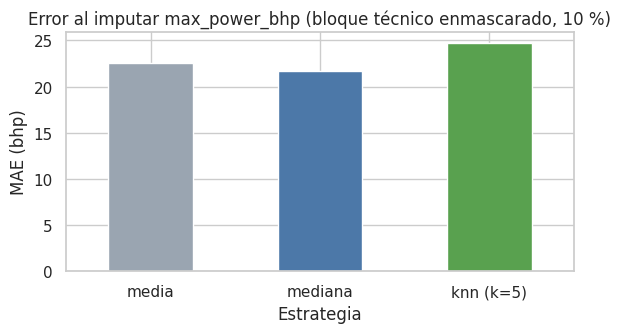

In [12]:
# --- Experimento de enmascaramiento POR BLOQUE: ¿qué estrategia recupera mejor el valor real de max_power_bhp? ---
tecnicas_cols = ['mileage_num', 'engine_cc', 'max_power_bhp', 'torque_nm', 'seats']
cols_imp = ['year', 'km_driven'] + tecnicas_cols
base = df3[cols_imp].copy()

completas = base.index[base[tecnicas_cols].notna().all(axis=1)]          # filas con ficha técnica completa
rng = np.random.RandomState(SEED)
idx_mask = rng.choice(completas, size=int(0.10 * len(completas)), replace=False)
real = base.loc[idx_mask, 'max_power_bhp']

enmascarado = base.copy()
enmascarado.loc[idx_mask, tecnicas_cols] = np.nan                         # se oculta TODO el bloque técnico

predicciones = {}
predicciones['media']   = np.full(len(idx_mask), enmascarado['max_power_bhp'].mean())
predicciones['mediana'] = np.full(len(idx_mask), enmascarado['max_power_bhp'].median())

esc = StandardScaler().fit(enmascarado)                       # KNN necesita variables en la misma escala
Z = KNNImputer(n_neighbors=5).fit_transform(esc.transform(enmascarado))
imputado_knn = pd.DataFrame(esc.inverse_transform(Z), index=enmascarado.index, columns=cols_imp)
predicciones['knn (k=5)'] = imputado_knn.loc[idx_mask, 'max_power_bhp'].values

tabla_imp = pd.DataFrame({
    nombre: {'MAE (bhp)': mean_absolute_error(real, p), 'RMSE (bhp)': np.sqrt(mean_squared_error(real, p))}
    for nombre, p in predicciones.items()
}).T.round(2)
display(tabla_imp)

# Estrategia elegida = la de menor MAE
traduccion = {'media': 'mean', 'mediana': 'median', 'knn (k=5)': 'knn'}
mejor_estrategia = tabla_imp['MAE (bhp)'].idxmin()
MEJOR_IMPUTADOR = traduccion[mejor_estrategia]
mae_elegida, mae_mediana = tabla_imp.loc[mejor_estrategia, 'MAE (bhp)'], tabla_imp.loc['mediana', 'MAE (bhp)']
print(f'\n➡ Estrategia elegida: {mejor_estrategia} (menor MAE). Se usará dentro del Pipeline.')
print(f'MAE de la elegida vs. la mediana global: {mae_elegida:.2f} vs {mae_mediana:.2f} bhp '
      f'({(1 - mae_elegida / mae_mediana) * 100:+.1f} % de mejora)')
print(f'(Alternativa "eliminar filas": perdería {sin_ficha.sum()} filas = {sin_ficha.mean()*100:.1f} % de los datos.)')

fig, ax = plt.subplots(figsize=(6, 3.5))
tabla_imp['MAE (bhp)'].plot.bar(ax=ax, color=['#9aa5b1', '#4c78a8', '#59a14f'], rot=0)
ax.set(title='Error al imputar max_power_bhp (bloque técnico enmascarado, 10 %)', xlabel='Estrategia', ylabel='MAE (bhp)')
plt.tight_layout(); plt.show()

✏️ **Decisión justificada de imputación**
- Se **descartó eliminar filas**: se perderían ≈ 3 % de los datos y las filas sin ficha técnica no parecen aleatorias (son anuncios incompletos; su precio mediano es mucho menor), así que borrarlas **sesgaría** la muestra hacia autos con ficha completa.
- Como los nulos son **de bloque**, para esas filas solo hay información de `year` y `km_driven` (y las categóricas); por eso se evaluó la imputación con el bloque completo oculto (ver el experimento y la nota de la sección 2.5).
- La media es sensible a la cola larga de potencias altas; la mediana es más robusta; el KNN estima la potencia con autos *parecidos* en año y kilometraje.
- Se elige la estrategia con **menor error** en el experimento (resultado impreso arriba: tabla, gráfico y % de mejora frente a la mediana).
- Importante: la imputación final **no se aplica aquí**, sino dentro del `Pipeline` y ajustada **solo con entrenamiento** (sección 2.8) para no filtrar información del conjunto de prueba.

## 2.6 Valores atípicos (diagramas de caja + regla del IQR)
Regla: un dato es atípico si está fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. El IQR **solo se usa para detectar y decidir**; no se recortan datos con estadísticos calculados sobre todo el dataset.

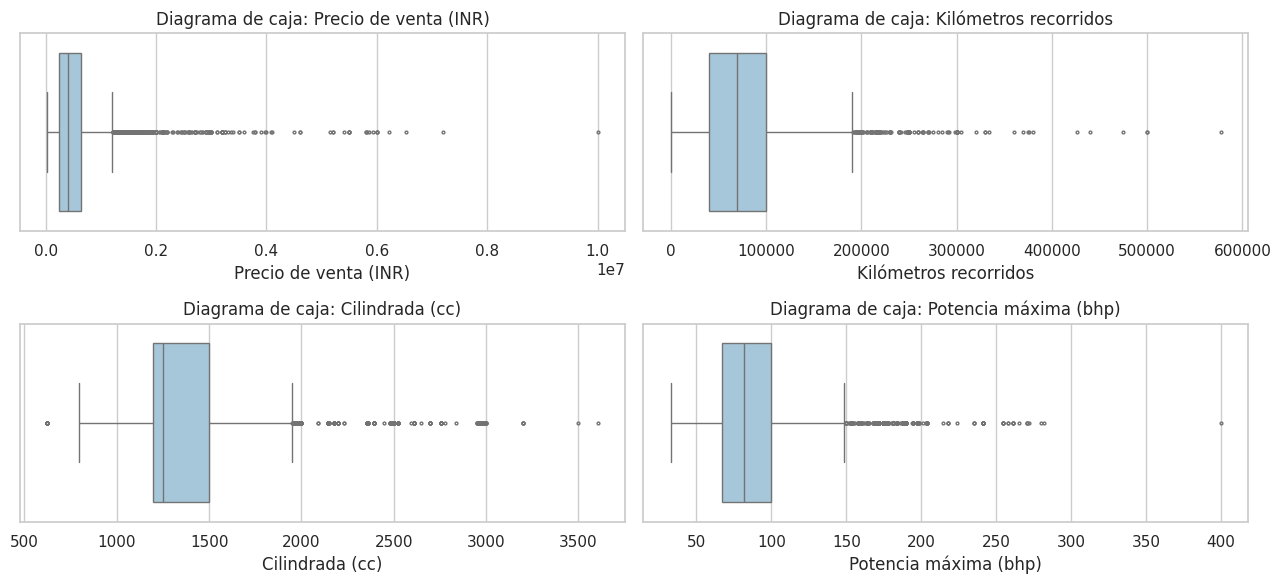

,límite inferior,límite superior,n atípicos,% atípicos
variable,,,,
selling_price,"-326,375.0000","1,210,625.0000",327,4.7200
km_driven,"-50,000.0000","190,000.0000",165,2.3800
engine_cc,745.5000,"1,949.5000",1206,17.4200
max_power_bhp,17.7500,149.3500,304,4.3900


Asimetría de selling_price     : 5.57
Asimetría de log(1+selling_price): -0.16


In [13]:
variables_out = ['selling_price', 'km_driven', 'engine_cc', 'max_power_bhp']
etiquetas = {'selling_price': 'Precio de venta (INR)', 'km_driven': 'Kilómetros recorridos',
             'engine_cc': 'Cilindrada (cc)', 'max_power_bhp': 'Potencia máxima (bhp)'}

fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for ax, c in zip(axes.ravel(), variables_out):
    sns.boxplot(x=df3[c], ax=ax, color='#9ecae1', fliersize=2)
    ax.set(title=f'Diagrama de caja: {etiquetas[c]}', xlabel=etiquetas[c])
plt.tight_layout(); plt.show()

def limites_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

filas = []
for c in variables_out:
    lo, hi = limites_iqr(df3[c].dropna())
    n = int(((df3[c] < lo) | (df3[c] > hi)).sum())
    filas.append({'variable': c, 'límite inferior': lo, 'límite superior': hi,
                  'n atípicos': n, '% atípicos': 100 * n / len(df3)})
display(pd.DataFrame(filas).set_index('variable').round(2))

print('Asimetría de selling_price     :', round(df3['selling_price'].skew(), 2))
print('Asimetría de log(1+selling_price):', round(np.log1p(df3['selling_price']).skew(), 2))

✏️ **Decisión sobre atípicos (una por variable)** — confirmar con la salida:

| Variable | Decisión | Justificación |
|---|---|---|
| `selling_price` | **Conservar + transformar con logaritmo** | Los precios altos (hasta 10 millones) son autos de lujo **reales**, no errores. Eliminarlos haría que el modelo no sirva justo para ese segmento. El log reduce la asimetría y estabiliza la varianza; el modelo se entrena con `log(1+precio)` y las métricas se reportan en INR. |
| `km_driven` | **Conservar** (tras eliminar los > 1 000 000 km de la sección 2.4) | Los kilometrajes altos restantes son plausibles (taxis, autos de uso intenso). |
| `engine_cc` | **Conservar** | Los "atípicos" son motores grandes de SUV/lujo: información legítima. |
| `max_power_bhp` | **Conservar** | Corresponde a autos de alto desempeño: es un predictor clave del precio. |

Los modelos basados en árboles son robustos a atípicos; para regresión lineal y red neuronal se mitiga el efecto con el logaritmo del objetivo y el escalado.

## 2.7 Ingeniería de características (≥ 2 variables nuevas)

| Variable nueva | Cómo se calcula | Utilidad |
|---|---|---|
| `age` | `REF_YEAR − year` | La **antigüedad** es más directa que el año para medir depreciación (cuanto más viejo, menos vale). |
| `km_per_year` | `km_driven / max(age, 1)` | Mide la **intensidad de uso**: 100 000 km en 2 años no es lo mismo que en 15. |
| `power_per_cc` | `max_power_bhp / engine_cc` | **Eficiencia del motor** (potencia por cilindrada): distingue motores turbo/deportivos de motores básicos. |
| `brand` | primera palabra de `name` | Reduce `name` (2 058 valores únicos, inutilizable) a unas ~30 marcas: la marca influye mucho en el precio. |

In [14]:
df4 = df3.copy()
df4['age']          = REF_YEAR - df4['year']
df4['km_per_year']  = df4['km_driven'] / df4['age'].clip(lower=1)
df4['power_per_cc'] = (df4['max_power_bhp'] / df4['engine_cc']).replace([np.inf, -np.inf], np.nan)

display(df4[['name', 'brand', 'year', 'age', 'km_driven', 'km_per_year', 'max_power_bhp', 'engine_cc', 'power_per_cc']].head(8))
print('Estadísticos de las variables nuevas:')
display(df4[['age', 'km_per_year', 'power_per_cc']].describe().T)

,name,brand,year,age,km_driven,km_per_year,max_power_bhp,engine_cc,power_per_cc
0,Maruti Swift Dzire VDI,Maruti,2014,6,145500,"24,250.0000",74.0000,"1,248.0000",0.0593
1,Skoda Rapid 1.5 TDI Ambition,Skoda,2014,6,120000,"20,000.0000",103.5200,"1,498.0000",0.0691
2,Honda City 2017-2020 EXi,Honda,2006,14,140000,"10,000.0000",78.0000,"1,497.0000",0.0521
3,Hyundai i20 Sportz Diesel,Hyundai,2010,10,127000,"12,700.0000",90.0000,"1,396.0000",0.0645
4,Maruti Swift VXI BSIII,Maruti,2007,13,120000,"9,230.7692",88.2000,"1,298.0000",0.0680
5,Hyundai Xcent 1.2 VTVT E Plus,Hyundai,2017,3,45000,"15,000.0000",81.8600,"1,197.0000",0.0684
6,Maruti Wagon R LXI DUO BSIII,Maruti,2007,13,175000,"13,461.5385",57.5000,"1,061.0000",0.0542
7,Maruti 800 DX BSII,Maruti,2001,19,5000,263.1579,37.0000,796.0000,0.0465


Estadísticos de las variables nuevas:


,count,mean,std,min,25%,50%,75%,max
age,"6,924.0000",6.5786,4.0781,0.0000,3.0000,6.0000,9.0000,37.0000
km_per_year,"6,924.0000","13,223.6993","9,348.3808",0.1111,"7,393.7500","11,111.1111","16,666.6667","120,000.0000"
power_per_cc,"6,715.0000",0.0625,0.0123,0.0213,0.0587,0.0642,0.0684,0.2031


## 2.8 Separación de X e y y preprocesamiento con `ColumnTransformer` + `Pipeline`

**Codificación de las categóricas (justificada según el tipo de variable):**
- `fuel`, `seller_type`, `transmission`, `brand` → **One-Hot**: son **nominales** (no hay orden natural). Un *Label Encoding* inventaría un orden falso (p. ej. Petrol < Diesel) que confundiría al modelo lineal y a la red neuronal. En `brand` se agrupan en una categoría "infrecuente" las marcas con menos de 20 registros (`min_frequency=20`) para no crear columnas casi vacías.
- `owner` → **Ordinal**: tiene un **orden real** (First < Second < Third < Fourth & Above); *Test Drive Car* se coloca al inicio (auto de demostración, sin dueños previos).

**Escalado:** `StandardScaler` en las variables numéricas. Es **necesario** para regresión lineal, KNN y red neuronal (sensibles a la escala) y **inofensivo** para los árboles (invariantes a escalas monótonas); se usa el mismo preprocesamiento para todos para que la comparación sea justa y para cumplir el requisito de la red neuronal de usar *las mismas variables*.

**Imputación:** estrategia elegida en la sección 2.5 (solo numéricas); `most_frequent` en categóricas por seguridad.

**Se excluyen de X:** `selling_price` (es el objetivo), `year` (redundante con `age`, correlación perfecta) y `name`, `mileage`, `engine`, `max_power`, `torque` (versiones en texto ya reemplazadas por sus equivalentes numéricos).

In [15]:
def hacer_imputador(nombre):
    if nombre == 'mean':   return SimpleImputer(strategy='mean')
    if nombre == 'median': return SimpleImputer(strategy='median')
    return KNNImputer(n_neighbors=5)

num_features = ['km_driven', 'mileage_num', 'engine_cc', 'max_power_bhp', 'torque_nm',
                'seats', 'age', 'km_per_year', 'power_per_cc']
nom_features = ['fuel', 'seller_type', 'transmission', 'brand']
ord_features = ['owner']
ORDEN_OWNER  = ['Test Drive Car', 'First Owner', 'Second Owner', 'Third Owner', 'Fourth & Above Owner']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('scaler',  StandardScaler()),
                          ('imputer', hacer_imputador(MEJOR_IMPUTADOR))]), num_features),
        ('nom', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot',  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                    min_frequency=20, sparse_output=False))]), nom_features),
        ('ord', OrdinalEncoder(categories=[ORDEN_OWNER], handle_unknown='use_encoded_value',
                               unknown_value=-1), ord_features),
    ],
    sparse_threshold=0, verbose_feature_names_out=False)

# Separación de X e y (todavía NO se ajusta ningún transformador)
X = df4[num_features + nom_features + ord_features]
y = df4['selling_price']
print(f'X: {X.shape} | y: {y.shape}')
print(f'Imputador usado en las numéricas: {MEJOR_IMPUTADOR}')
preprocessor

X: (6924, 14) | y: (6924,)
Imputador usado en las numéricas: median


ColumnTransformer(sparse_threshold=0,
                  transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler()),
                                                 ('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['km_driven', 'mileage_num', 'engine_cc',
                                  'max_power_bhp', 'torque_nm', 'seats', 'age',
                                  'km_per_year', 'power_per_cc']),
                                ('nom',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=20,
                                                                sparse_output=False))]),
                                 ['fuel', 'seller_type', 'transmission',
                                  'brand']),
                                ('ord',
                                 OrdinalEncoder(categories=[['Test Drive Car',
                                                             'First Owner',
                                                             'Second Owner',
                                                             'Third Owner',
                                                             'Fourth & Above '
                                                             'Owner']],
                                                handle_unknown='use_encoded_value',
                                                unknown_value=-1),
                                 ['owner'])],
                  verbose_feature_names_out=False)

## 2.9 🏁 Reto del Bloque 2: fuga de datos (*data leakage*)

**¿Qué es?** Es cuando, durante el entrenamiento, el modelo accede (directa o indirectamente) a información que **no estaría disponible al predecir casos nuevos**, típicamente información del conjunto de prueba. Produce métricas **optimistas** que luego no se cumplen en la realidad.

**Formas de fuga posibles en este dataset y cómo se evitan:**
1. **Filas duplicadas repartidas entre train y test** (¡aquí hay 1 202!): el modelo "memoriza" una fila en entrenamiento y la "predice" en prueba. → *Se eliminan los duplicados antes de dividir.*
2. **Escalar/imputar con estadísticos de todo el dataset** (media, mediana, KNN) antes de dividir: el conjunto de prueba influye en las transformaciones. → *Todo está dentro de un `Pipeline`, que se ajusta (`fit`) solo con entrenamiento; en la validación cruzada se reajusta en cada pliegue.*
3. **Codificar categorías o usar el precio medio por marca** (*target encoding*) calculado con todos los datos. → *No se usa target encoding; el One-Hot se aprende solo en train.*

**Demostración concreta con los duplicados:** mismo modelo (Random Forest), misma semilla, con y sin duplicados.

In [16]:
cols_demo = ['year', 'km_driven', 'engine_cc', 'max_power_bhp', 'mileage_num', 'seats']

def experimento_fuga(d):
    d = d.reset_index(drop=True)
    tr, te = train_test_split(d.index, test_size=0.2, random_state=SEED)
    llave = pd.util.hash_pandas_object(d[cols_demo + ['selling_price']], index=False)   # "huella" de cada fila
    copias_en_test = llave.loc[te].isin(set(llave.loc[tr])).mean() * 100                # % de test con copia exacta en train
    rf = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
    rf.fit(d.loc[tr, cols_demo].fillna(-1), np.log1p(d.loc[tr, 'selling_price']))
    r2 = r2_score(np.log1p(d.loc[te, 'selling_price']), rf.predict(d.loc[te, cols_demo].fillna(-1)))
    return copias_en_test, r2

con_dup = parsear_columnas(df_raw)          # dataset CON duplicados
sin_dup = df4                               # dataset SIN duplicados (ya limpio)
c1, r1 = experimento_fuga(con_dup)
c2, r2_ = experimento_fuga(sin_dup)

demo = pd.DataFrame({'% de filas de test con copia exacta en train': [c1, c2],
                     'R² en test (escala log)': [r1, r2_]},
                    index=['Con duplicados (fuga)', 'Sin duplicados (correcto)']).round(3)
display(demo)
print(f'El R² está inflado en {r1 - r2_:+.3f} por la fuga: el modelo "recuerda" filas que ya vio en entrenamiento.')

,% de filas de test con copia exacta en train,R² en test (escala log)
Con duplicados (fuga),20.7870,0.9250
Sin duplicados (correcto),0.9390,0.9040


El R² está inflado en +0.021 por la fuga: el modelo "recuerda" filas que ya vio en entrenamiento.


✏️ **Conclusión del reto:** con duplicados, una parte del conjunto de prueba son copias exactas de filas de entrenamiento y el R² sale **artificialmente más alto**. Al eliminarlos se obtiene una estimación **honesta** del desempeño. Además, al estar el escalado, la imputación y la codificación dentro del `Pipeline`, ningún estadístico del conjunto de prueba se filtra al entrenamiento.

# Bloque 3. Análisis exploratorio y visualización

Se usa el conjunto **ya limpio** (`df4`) completo con fines **descriptivos**. Ningún estadístico del EDA se usa para ajustar modelos (eso ocurre solo dentro del `Pipeline`, con datos de entrenamiento). Para los gráficos se añade `log_price` (solo para graficar; **no** es parte de X).

Para cada gráfica se responde: *¿qué patrón se observa? ¿qué información aporta? ¿qué limitaciones tiene?*

In [17]:
eda = df4.copy()
eda['log_price'] = np.log1p(eda['selling_price'])      # solo para visualizar
print('Registros en el EDA:', len(eda))

Registros en el EDA: 6924


## (a) Distribución de la variable objetivo

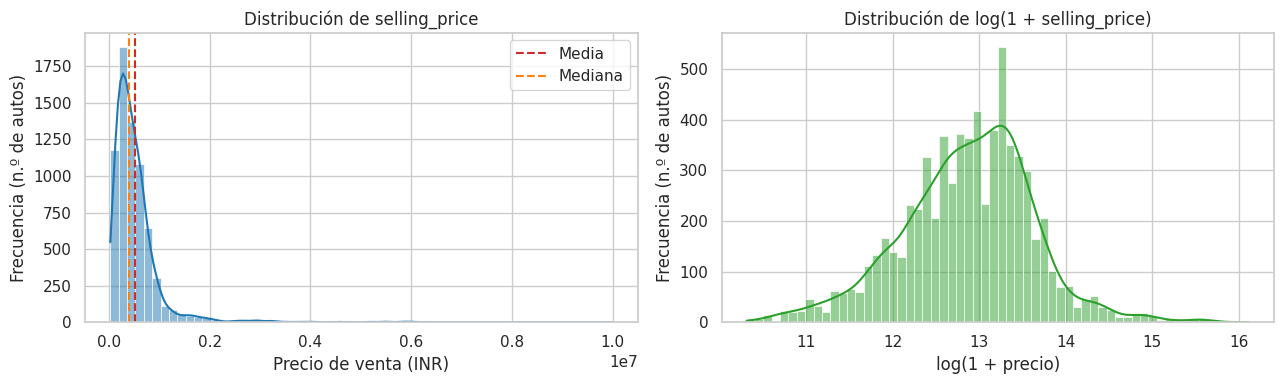

Media: 517,268 | Mediana: 400,000 | Asimetría: 5.57 → con log: -0.16


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(eda['selling_price'], kde=True, bins=60, ax=ax[0], color='tab:blue')
ax[0].set(title='Distribución de selling_price', xlabel='Precio de venta (INR)', ylabel='Frecuencia (n.º de autos)')
ax[0].axvline(eda['selling_price'].mean(),   color='tab:red',    ls='--', label='Media')
ax[0].axvline(eda['selling_price'].median(), color='tab:orange', ls='--', label='Mediana')
ax[0].legend()

sns.histplot(eda['log_price'], kde=True, bins=60, ax=ax[1], color='tab:green')
ax[1].set(title='Distribución de log(1 + selling_price)', xlabel='log(1 + precio)', ylabel='Frecuencia (n.º de autos)')
plt.tight_layout(); plt.show()

print(f"Media: {eda['selling_price'].mean():,.0f} | Mediana: {eda['selling_price'].median():,.0f} | "
      f"Asimetría: {eda['selling_price'].skew():.2f} → con log: {eda['log_price'].skew():.2f}")

✏️ **Interpretación (a)**
- **Patrón:** distribución **muy asimétrica a la derecha**: la mayoría de autos cuesta entre ~250 mil y ~700 mil INR y hay una cola larga hasta 10 millones. La media supera claramente a la mediana. Con el logaritmo la forma es casi simétrica.
- **Información que aporta:** justifica entrenar con `log(1+precio)`; el precio "típico" se describe mejor con la mediana que con la media.
- **Limitaciones:** el histograma mezcla segmentos muy distintos (económicos, SUV, lujo) y oculta sus diferencias; al usar el log, los errores se miden en escala multiplicativa (porcentajes) y no en rupias.

## (b) Histogramas de variables numéricas relevantes

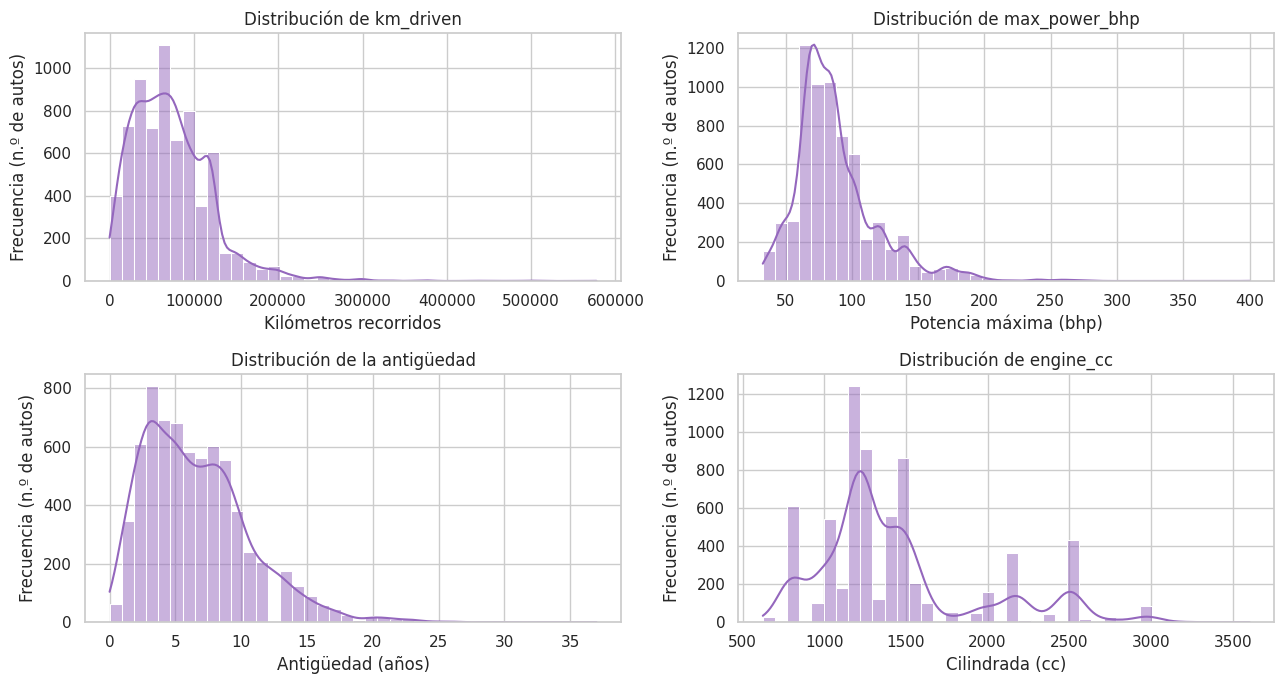

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (c, t, xl) in zip(axes.ravel(), [
        ('km_driven', 'Distribución de km_driven', 'Kilómetros recorridos'),
        ('max_power_bhp', 'Distribución de max_power_bhp', 'Potencia máxima (bhp)'),
        ('age', 'Distribución de la antigüedad', 'Antigüedad (años)'),
        ('engine_cc', 'Distribución de engine_cc', 'Cilindrada (cc)')]):
    sns.histplot(eda[c].dropna(), kde=True, bins=40, ax=ax, color='tab:purple')
    ax.set(title=t, xlabel=xl, ylabel='Frecuencia (n.º de autos)')
plt.tight_layout(); plt.show()

✏️ **Interpretación (b)**
- **Patrón:** `km_driven` y `max_power_bhp` tienen **cola larga a la derecha**; la antigüedad se concentra entre ~3 y ~10 años; `engine_cc` presenta **picos** en cilindradas comerciales típicas (≈ 800, 1 000, 1 200, 1 500 y 2 500 cc).
- **Información que aporta:** el mercado está dominado por autos compactos de motor pequeño y uso moderado; la asimetría anticipa que los modelos lineales se beneficiarán del escalado.
- **Limitaciones:** `engine_cc` es casi discreta (los picos son tamaños de motor comerciales) y el kilometraje es declarado por el vendedor (posible error). Los histogramas no muestran la relación con el precio.

## (c) Diagramas de caja: precio según categorías

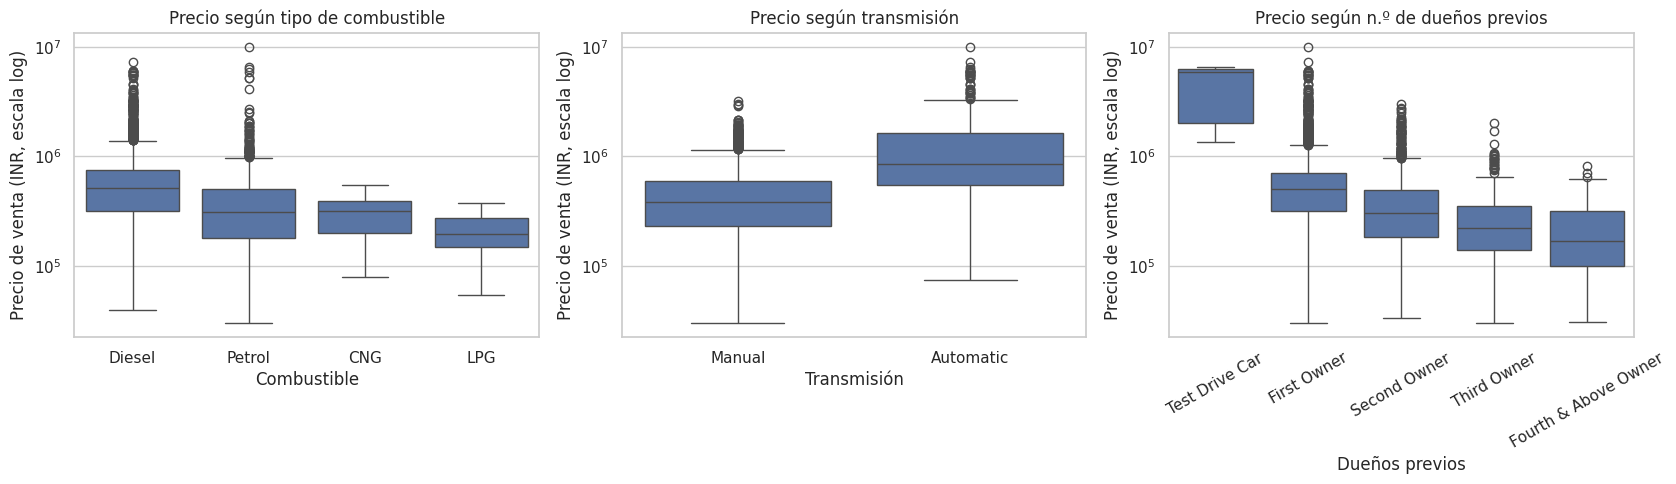

Mediana del precio por grupo (INR):
             median  count
fuel                      
CNG    320,000.0000     56
Diesel 520,000.0000   3754
LPG    195,500.0000     38
Petrol 310,000.0000   3076 

                   median  count
transmission                    
Automatic    850,000.0000    584
Manual       385,000.0000   6340 

                             median  count
owner                                     
First Owner            500,000.0000   4241
Fourth & Above Owner   170,000.0000    169
Second Owner           305,000.0000   1973
Test Drive Car       5,923,000.0000      5
Third Owner            222,500.0000    536 



In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(data=eda, x='fuel', y='selling_price', ax=ax[0], order=['Diesel', 'Petrol', 'CNG', 'LPG'])
ax[0].set(title='Precio según tipo de combustible', xlabel='Combustible', ylabel='Precio de venta (INR, escala log)')
sns.boxplot(data=eda, x='transmission', y='selling_price', ax=ax[1])
ax[1].set(title='Precio según transmisión', xlabel='Transmisión', ylabel='Precio de venta (INR, escala log)')
sns.boxplot(data=eda, x='owner', y='selling_price', ax=ax[2], order=ORDEN_OWNER)
ax[2].set(title='Precio según n.º de dueños previos', xlabel='Dueños previos', ylabel='Precio de venta (INR, escala log)')
ax[2].tick_params(axis='x', rotation=30)
for a in ax: a.set_yscale('log')
plt.tight_layout(); plt.show()

print('Mediana del precio por grupo (INR):')
for c in ['fuel', 'transmission', 'owner']:
    print(eda.groupby(c)['selling_price'].agg(['median', 'count']).round(0).to_string(), '\n')

✏️ **Interpretación (c)**
- **Patrón:** los autos **automáticos** tienen una mediana de precio claramente mayor que los manuales; los **diésel** son más caros que los de gasolina; el precio **baja a medida que aumentan los dueños previos**. CNG/LPG muestran precios bajos.
- **Información que aporta:** `transmission`, `fuel` y `owner` discriminan el precio y son buenos candidatos como predictores.
- **Limitaciones:** hay **solapamiento** grande entre cajas (hay manuales caros y automáticos baratos), por lo que ninguna variable por sí sola basta; hay **confusión** (los automáticos suelen ser también más potentes y nuevos); CNG, LPG y *Test Drive Car* tienen muy pocos registros y sus cajas son poco fiables.

## (d) Mapa de calor de correlaciones

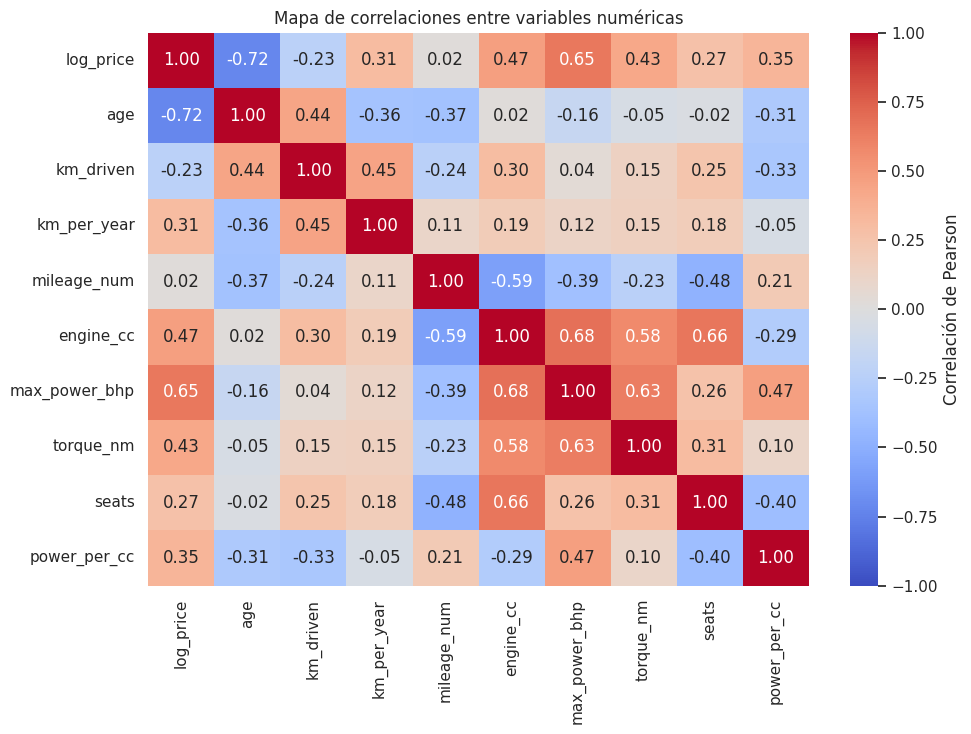

Correlación con log_price (de mayor a menor valor absoluto):
age             -0.7190
max_power_bhp    0.6550
engine_cc        0.4740
torque_nm        0.4280
power_per_cc     0.3450
km_per_year      0.3120
seats            0.2670
km_driven       -0.2310
mileage_num      0.0170


In [21]:
cols_corr = ['log_price', 'age', 'km_driven', 'km_per_year', 'mileage_num', 'engine_cc',
             'max_power_bhp', 'torque_nm', 'seats', 'power_per_cc']
corr = eda[cols_corr].corr(method='pearson')

plt.figure(figsize=(10, 7.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlación de Pearson'})
plt.title('Mapa de correlaciones entre variables numéricas')
plt.tight_layout(); plt.show()

print('Correlación con log_price (de mayor a menor valor absoluto):')
print(corr['log_price'].drop('log_price').sort_values(key=np.abs, ascending=False).round(3).to_string())

✏️ **Interpretación (d)**
- **Patrón:** el precio (en log) se correlaciona **positivamente** con `max_power_bhp`, `engine_cc` y `torque_nm`, y **negativamente** con `age` y `km_driven`. Cilindrada, potencia y par están **muy correlacionados entre sí** (multicolinealidad).
- **Información que aporta:** señala las variables con más poder predictivo y advierte que los coeficientes de la regresión lineal serán difíciles de interpretar por la colinealidad (los árboles no sufren esto).
- **Limitaciones:** Pearson mide solo relaciones **lineales** y es sensible a atípicos; no refleja las categóricas ni las interacciones.

## (e) Dispersión de dos variables diferenciando grupos

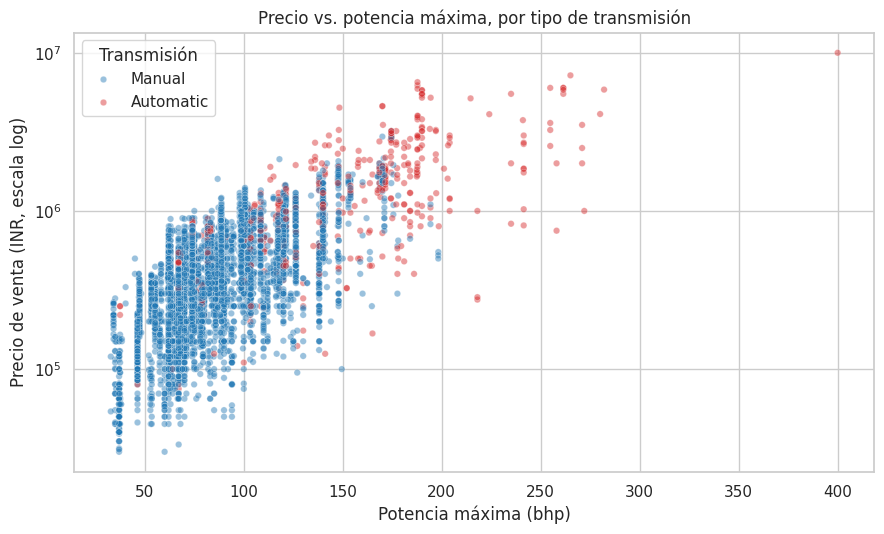

In [22]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=eda, x='max_power_bhp', y='selling_price', hue='transmission',
                alpha=0.45, s=22, palette={'Manual': 'tab:blue', 'Automatic': 'tab:red'})
plt.yscale('log')
plt.title('Precio vs. potencia máxima, por tipo de transmisión')
plt.xlabel('Potencia máxima (bhp)'); plt.ylabel('Precio de venta (INR, escala log)')
plt.legend(title='Transmisión')
plt.tight_layout(); plt.show()

✏️ **Interpretación (e)**
- **Patrón:** relación **positiva y aproximadamente lineal en escala logarítmica**: a mayor potencia, mayor precio. Los automáticos (rojo) se concentran en la zona alta de potencia y de precio.
- **Información que aporta:** confirma que `max_power_bhp` es un predictor central y que `transmission` aporta información adicional a una potencia dada.
- **Limitaciones:** la dispersión vertical es amplia (autos con igual potencia y precios muy distintos, por antigüedad, marca y kilometraje); hay **sobreposición de puntos** en la zona densa; no se controla el efecto de la antigüedad.

## (f) Gráfico de pares (*pairplot*) y barras agrupadas

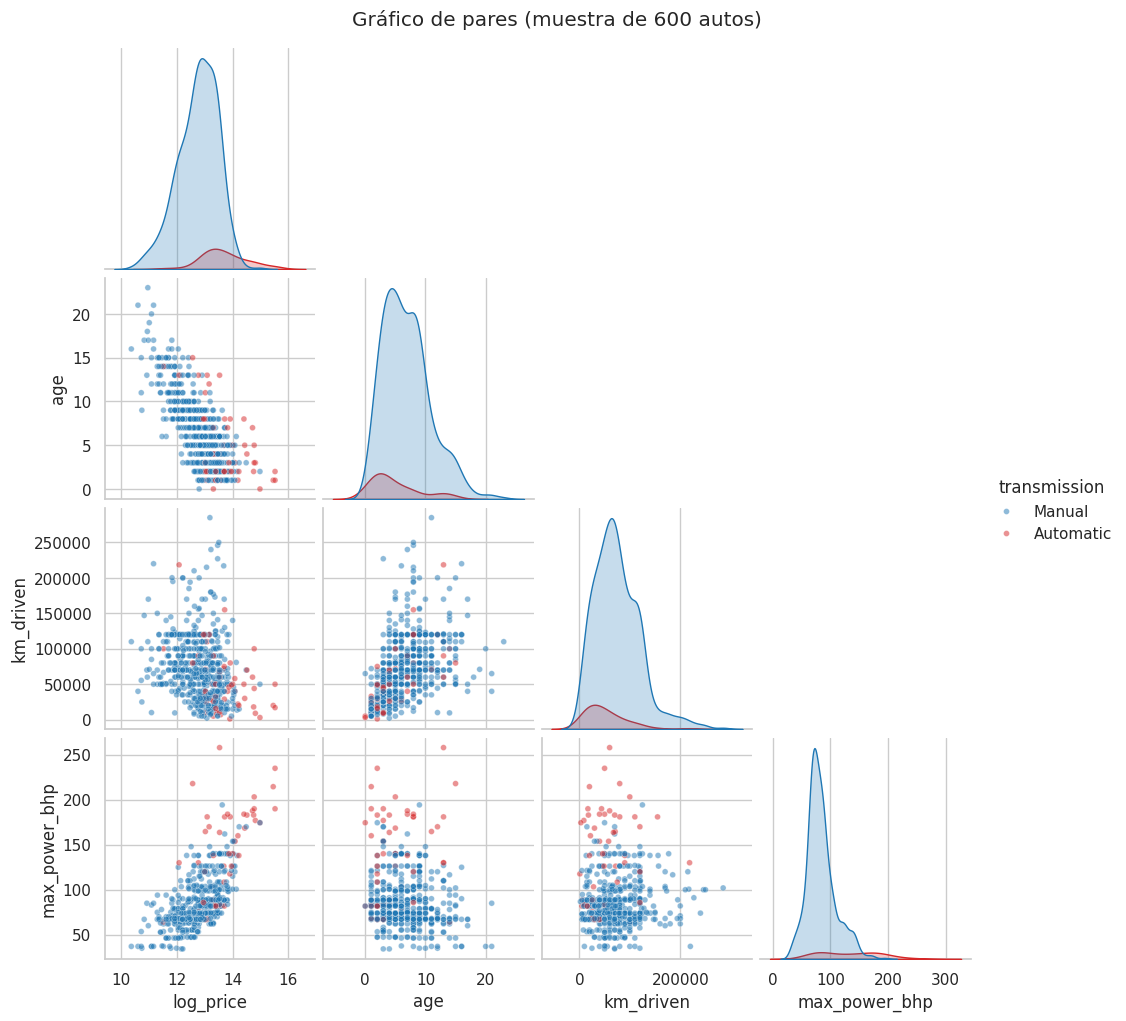

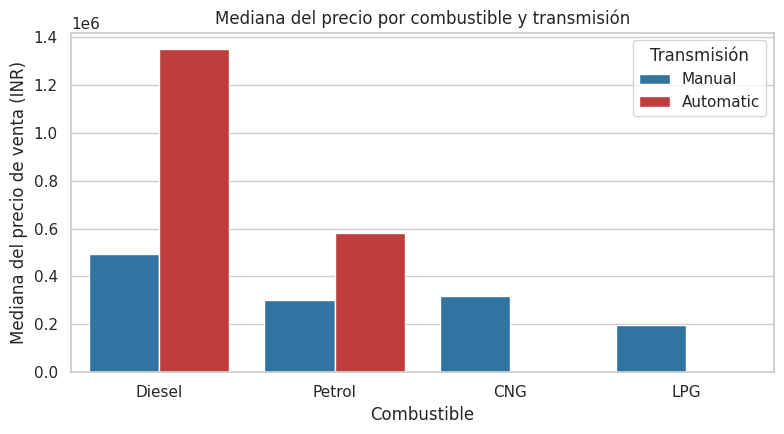

transmission  Automatic  Manual
fuel                           
CNG                   0      56
Diesel              298    3456
LPG                   0      38
Petrol              286    2790


In [23]:
muestra = eda.sample(600, random_state=SEED)[['log_price', 'age', 'km_driven', 'max_power_bhp', 'transmission']]
g = sns.pairplot(muestra, hue='transmission', corner=True, plot_kws={'alpha': 0.5, 's': 18},
                 palette={'Manual': 'tab:blue', 'Automatic': 'tab:red'})
g.figure.suptitle('Gráfico de pares (muestra de 600 autos)', y=1.02)
plt.show()

plt.figure(figsize=(8, 4.5))
sns.barplot(data=eda, x='fuel', y='selling_price', hue='transmission', estimator=np.median, errorbar=None,
            order=['Diesel', 'Petrol', 'CNG', 'LPG'], palette={'Manual': 'tab:blue', 'Automatic': 'tab:red'})
plt.title('Mediana del precio por combustible y transmisión')
plt.xlabel('Combustible'); plt.ylabel('Mediana del precio de venta (INR)')
plt.legend(title='Transmisión')
plt.tight_layout(); plt.show()
print(eda.groupby(['fuel', 'transmission']).size().unstack(fill_value=0).to_string())

✏️ **Interpretación (f)**
- **Patrón:** en el *pairplot*, `log_price` baja con la antigüedad y sube con la potencia; los automáticos ocupan la zona de mayor potencia y precio. En las barras, **dentro de cada combustible el automático tiene mayor mediana que el manual**.
- **Información que aporta:** muestra varias relaciones a la vez y confirma que el efecto de la transmisión no se debe solo al combustible.
- **Limitaciones:** el *pairplot* usa solo una muestra de 600 autos y varias variables; en CNG/LPG hay muy pocos automáticos (la mediana de un grupo de 0–2 autos no es confiable); la mediana no muestra la dispersión.

## (g) Gráfica adicional: depreciación por antigüedad y precio por marca

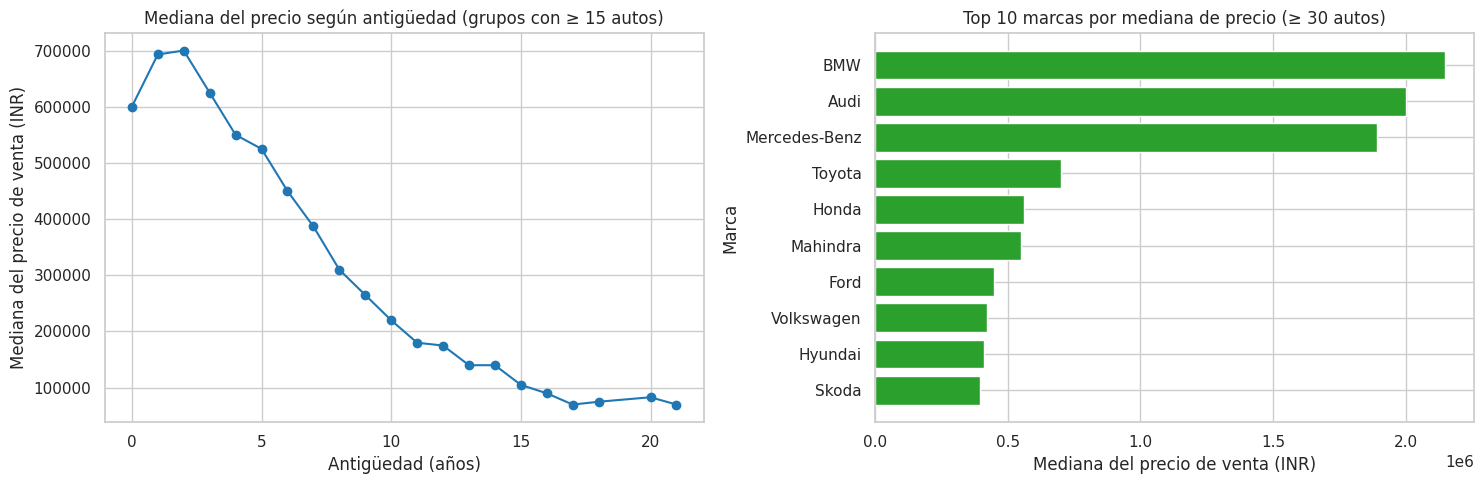

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

por_edad = eda.groupby('age')['selling_price'].agg(['median', 'count'])
por_edad = por_edad[por_edad['count'] >= 15]
ax[0].plot(por_edad.index, por_edad['median'], marker='o', color='tab:blue')
ax[0].set(title='Mediana del precio según antigüedad (grupos con ≥ 15 autos)',
          xlabel='Antigüedad (años)', ylabel='Mediana del precio de venta (INR)')

por_marca = eda.groupby('brand')['selling_price'].agg(['median', 'count'])
por_marca = por_marca[por_marca['count'] >= 30].sort_values('median', ascending=False).head(10)
ax[1].barh(por_marca.index[::-1], por_marca['median'][::-1], color='tab:green')
ax[1].set(title='Top 10 marcas por mediana de precio (≥ 30 autos)',
          xlabel='Mediana del precio de venta (INR)', ylabel='Marca')
plt.tight_layout(); plt.show()

✏️ **Interpretación (g)**
- **Patrón:** el precio mediano **cae con la antigüedad** (depreciación), con una pendiente fuerte en los primeros años; el ranking de marcas lo lideran las **marcas premium**.
- **Información que aporta:** valida `age` y `brand` como variables de ingeniería útiles; la depreciación no es lineal, lo que favorece a modelos no lineales.
- **Limitaciones:** el ranking de marcas mezcla efecto marca con efecto modelo/potencia (un efecto de composición) y solo incluye marcas con ≥ 30 registros; los autos muy antiguos son pocos y su mediana es inestable.

## 🏁 Reto del Bloque 3: análisis estadístico, correlación vs. causalidad y desbalance
Se respaldan hallazgos visuales con pruebas formales:
1. **Spearman** (monótona, robusta a atípicos) y **Pearson** (sobre log del precio) entre potencia y precio.
2. **Prueba t de Welch** y **Mann-Whitney** para comparar el precio entre transmisión automática y manual.

In [25]:
# 1) Correlación potencia – precio
v = eda[['max_power_bhp', 'selling_price', 'log_price']].dropna()
rho, p_rho = stats.spearmanr(v['max_power_bhp'], v['selling_price'])
r, p_r     = stats.pearsonr(v['max_power_bhp'], v['log_price'])
print(f'Spearman (potencia vs precio)      : rho = {rho:.3f} | p = {p_rho:.2e}')
print(f'Pearson  (potencia vs log precio)  : r   = {r:.3f} | p = {p_r:.2e}')

# 2) Comparación de medias/medianas: automático vs manual
auto   = eda.loc[eda['transmission'] == 'Automatic', 'log_price']
manual = eda.loc[eda['transmission'] == 'Manual',    'log_price']
t, p_t = stats.ttest_ind(auto, manual, equal_var=False)
u, p_u = stats.mannwhitneyu(auto, manual, alternative='two-sided')
med_a = eda.loc[eda['transmission'] == 'Automatic', 'selling_price'].median()
med_m = eda.loc[eda['transmission'] == 'Manual',    'selling_price'].median()
print(f'\nPrueba t de Welch (log precio)     : t = {t:.2f} | p = {p_t:.2e}')
print(f'Mann-Whitney U                     : U = {u:,.0f} | p = {p_u:.2e}')
print(f'Mediana automático = {med_a:,.0f} INR | manual = {med_m:,.0f} INR | razón = {med_a/med_m:.2f}x')

# 3) Regresión: no aplica desbalance de clases, pero sí se revisa el "desbalance" del objetivo (asimetría)
print(f'\nDesbalance de clases: no aplica (regresión). Asimetría del objetivo: {eda["selling_price"].skew():.2f}')

Spearman (potencia vs precio)      : rho = 0.635 | p = 0.00e+00
Pearson  (potencia vs log precio)  : r   = 0.655 | p = 0.00e+00

Prueba t de Welch (log precio)     : t = 27.05 | p = 3.61e-109
Mann-Whitney U                     : U = 3,016,605 | p = 2.92e-140
Mediana automático = 850,000 INR | manual = 385,000 INR | razón = 2.21x

Desbalance de clases: no aplica (regresión). Asimetría del objetivo: 5.57


✏️ **Interpretación del reto** (confirmar con la salida):
- Spearman y Pearson muestran una relación **positiva fuerte** entre potencia y precio, con p-valores prácticamente cero. Las pruebas t de Welch y Mann-Whitney detectan una diferencia **estadísticamente significativa** entre automáticos y manuales, con una razón de medianas muy superior a 1.
- **Correlación ≠ causalidad.** Que la potencia correlacione con el precio **no significa que aumentar la potencia de un auto cause que valga más**: ambas variables dependen de factores comunes (segmento del auto, marca, tamaño, año de lanzamiento). Del mismo modo, los automáticos son más caros en parte porque se ofrecen en **modelos más nuevos y de gama más alta**. Los modelos predictivos aprovechan **asociaciones** para estimar, pero no sirven para afirmar que cambiar una característica cambiará el precio.
- Con n tan grande (miles de autos), casi cualquier diferencia sale "significativa"; por eso importa el **tamaño del efecto** (la razón de medianas) y no solo el p-valor.
- **Clasificación/desbalance:** no aplica (es regresión). El análogo es la fuerte asimetría del precio, que se maneja con la transformación logarítmica.

# Bloque 4. Modelos tradicionales de predicción

**Estrategia:**
- División **80 % entrenamiento / 20 % prueba** con semilla fija (`random_state=42`). No se estratifica porque es regresión.
- **4 modelos:** Regresión lineal múltiple, Árbol de decisión, Random Forest y Gradient Boosting.
- Cada modelo se envuelve en `TransformedTargetRegressor(log1p / expm1)`: se **entrena sobre `log(1+precio)`** (por la asimetría) pero **predice y se evalúa en INR**, así R², MAE y RMSE están en unidades interpretables.
- El preprocesamiento (`preprocessor`) va **dentro** del Pipeline: se ajusta **solo con los datos de entrenamiento** (y en cada pliegue de la validación cruzada).
- Validación cruzada **k = 5** (media ± desviación estándar de R², y además MAE y RMSE), calculada **solo sobre el entrenamiento**.
- El modelo se **selecciona con el MAE de la validación cruzada** (sección 4.4), **no** con el conjunto de prueba: la prueba se usa una sola vez, para confirmar.
- Optimización de hiperparámetros con `GridSearchCV` en Gradient Boosting.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
print(f'Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}')
print(f'Mediana del precio — train: {y_train.median():,.0f} | test: {y_test.median():,.0f}')

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def metricas(y_real, y_pred):
    return {'R2': r2_score(y_real, y_pred),
            'MAE': mean_absolute_error(y_real, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
            'MAPE_%': np.mean(np.abs((np.asarray(y_real) - y_pred) / np.asarray(y_real))) * 100}

def armar(modelo):
    """Pipeline completo: preprocesamiento (ajustado solo en train) + modelo, entrenado sobre log(1+precio)."""
    return TransformedTargetRegressor(
        regressor=Pipeline([('prep', clone(preprocessor)), ('model', modelo)]),
        func=np.log1p, inverse_func=np.expm1)

Entrenamiento: (5539, 14) | Prueba: (1385, 14)
Mediana del precio — train: 400,000 | test: 400,000


## 4.1 Entrenamiento, validación cruzada (k = 5) y métricas
Además del R², se calculan el **MAE y el RMSE de validación cruzada** (en INR). Razón: el R² en INR es muy sensible a unos pocos autos de lujo (por eso su desviación entre pliegues es relativamente alta), mientras que MAE y RMSE se interpretan directamente como "rupias de error".

In [27]:
modelos = {
    'Regresión lineal':  LinearRegression(),
    'Árbol de decisión': DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=SEED),
    'Random Forest':     RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    'Gradient Boosting': GradientBoostingRegressor(random_state=SEED),
}

SCORING = {'r2': 'r2', 'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}

def resumen_cv(pipe):
    """Validación cruzada k=5 SOLO con entrenamiento (el preprocesamiento se reajusta en cada pliegue)."""
    cv = cross_validate(pipe, X_train, y_train, cv=kf, scoring=SCORING)
    return {'CV_R2_media': cv['test_r2'].mean(), 'CV_R2_std': cv['test_r2'].std(),
            'CV_MAE': -cv['test_mae'].mean(), 'CV_RMSE': -cv['test_rmse'].mean()}

filas, ajustados = [], {}
for nombre, m in modelos.items():
    pipe = armar(m)
    cv = resumen_cv(pipe)
    pipe.fit(X_train, y_train)
    ajustados[nombre] = pipe
    met_te = metricas(y_test, pipe.predict(X_test))
    filas.append({'Modelo': nombre,
                  'R2_train': r2_score(y_train, pipe.predict(X_train)),
                  **cv,
                  'R2_test': met_te['R2'], 'MAE': met_te['MAE'], 'RMSE': met_te['RMSE'], 'MAPE_%': met_te['MAPE_%']})
    print(f'✓ {nombre:20s} CV R² = {cv["CV_R2_media"]:.3f} ± {cv["CV_R2_std"]:.3f} | CV MAE = {cv["CV_MAE"]:,.0f} | R² test = {met_te["R2"]:.3f}')

res_base = pd.DataFrame(filas).set_index('Modelo')
display(res_base.round(3))

✓ Regresión lineal     CV R² = 0.875 ± 0.029 | CV MAE = 93,736 | R² test = 0.869
✓ Árbol de decisión    CV R² = 0.832 ± 0.024 | CV MAE = 94,411 | R² test = 0.846
✓ Random Forest        CV R² = 0.864 ± 0.043 | CV MAE = 79,778 | R² test = 0.922
✓ Gradient Boosting    CV R² = 0.860 ± 0.039 | CV MAE = 85,371 | R² test = 0.908


,R2_train,CV_R2_media,CV_R2_std,CV_MAE,CV_RMSE,R2_test,MAE,RMSE,MAPE_%
Modelo,,,,,,,,,
Regresión lineal,0.8850,0.8750,0.0290,"93,735.7440","177,531.9910",0.8690,"94,628.2980","204,022.1090",20.2920
Árbol de decisión,0.9240,0.8320,0.0240,"94,410.5710","206,441.4750",0.8460,"95,145.2580","221,435.1470",20.1610
Random Forest,0.9620,0.8640,0.0430,"79,777.6290","184,357.1130",0.9220,"76,838.9680","157,434.5710",17.1420
Gradient Boosting,0.9180,0.8600,0.0390,"85,371.4300","188,173.7180",0.9080,"81,279.8700","170,637.8030",17.6460


## 4.2 Optimización de hiperparámetros (`GridSearchCV`) en Gradient Boosting

In [28]:
grid = {
    'regressor__model__n_estimators': [200, 400],
    'regressor__model__learning_rate': [0.05, 0.1],
    'regressor__model__max_depth': [3, 5],
}
gs = GridSearchCV(armar(GradientBoostingRegressor(random_state=SEED)), grid,
                  cv=kf, scoring='r2', n_jobs=-1, refit=True)
gs.fit(X_train, y_train)

print('Mejores hiperparámetros:', {k.split('__')[-1]: v for k, v in gs.best_params_.items()})
print(f'Mejor R² en validación cruzada: {gs.best_score_:.3f}')
top = pd.DataFrame(gs.cv_results_)[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']] \
        .sort_values('rank_test_score').head(5)
top['params'] = top['params'].apply(lambda d: {k.split('__')[-1]: v for k, v in d.items()})
display(top)

gb_opt = gs.best_estimator_
ajustados['Gradient Boosting (optimizado)'] = gb_opt
cv_opt = resumen_cv(clone(gb_opt))          # mismos hiperparámetros y mismos pliegues -> MAE/RMSE de CV del modelo optimizado
met = metricas(y_test, gb_opt.predict(X_test))
res_base.loc['Gradient Boosting (optimizado)'] = {
    'R2_train': r2_score(y_train, gb_opt.predict(X_train)),
    **cv_opt,
    'R2_test': met['R2'], 'MAE': met['MAE'], 'RMSE': met['RMSE'], 'MAPE_%': met['MAPE_%']}

Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 400}
Mejor R² en validación cruzada: 0.879


,params,mean_test_score,std_test_score,rank_test_score
5,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.8792,0.0447,1
4,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.8744,0.0385,2
3,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.8715,0.0450,3
7,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.8715,0.0501,4
6,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.8677,0.0529,5


## 4.3 Tabla comparativa de modelos tradicionales
Ordenada por el **MAE de validación cruzada** (criterio de selección, calculado solo con entrenamiento). Se usa el MAE y no el R² ni el RMSE porque estos dos están dominados por unos pocos autos de lujo (de ahí la desviación alta del R² entre pliegues), mientras que el MAE refleja el error típico, que es lo que le cuesta dinero al usuario. Las columnas de *test* se muestran para confirmar, no para decidir.

,R2_train,CV_R2_media,CV_R2_std,CV_MAE,CV_RMSE,R2_test,MAE,RMSE,MAPE_%
Modelo,,,,,,,,,
Gradient Boosting (optimizado),0.9620,0.8790,0.0450,"77,740.3600","173,759.1920",0.9260,"74,699.5690","153,346.4860",16.4230
Random Forest,0.9620,0.8640,0.0430,"79,777.6290","184,357.1130",0.9220,"76,838.9680","157,434.5710",17.1420
Gradient Boosting,0.9180,0.8600,0.0390,"85,371.4300","188,173.7180",0.9080,"81,279.8700","170,637.8030",17.6460
Regresión lineal,0.8850,0.8750,0.0290,"93,735.7440","177,531.9910",0.8690,"94,628.2980","204,022.1090",20.2920
Árbol de decisión,0.9240,0.8320,0.0240,"94,410.5710","206,441.4750",0.8460,"95,145.2580","221,435.1470",20.1610


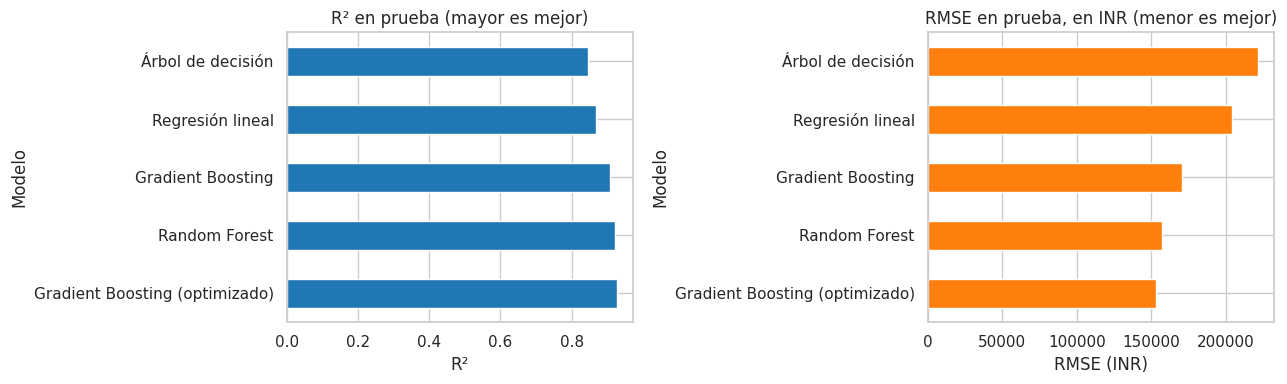

In [29]:
res_trad = res_base.sort_values('CV_MAE')
display(res_trad.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
res_trad['R2_test'].plot.barh(ax=ax[0], color='tab:blue')
ax[0].set(title='R² en prueba (mayor es mejor)', xlabel='R²', ylabel='Modelo')
res_trad['RMSE'].plot.barh(ax=ax[1], color='tab:orange')
ax[1].set(title='RMSE en prueba, en INR (menor es mejor)', xlabel='RMSE (INR)', ylabel='Modelo')
plt.tight_layout(); plt.show()

## 4.4 Valores reales vs. predichos y análisis de residuos
Se grafica el modelo con **menor MAE en validación cruzada** (seleccionado solo con datos de entrenamiento; puedes forzar otro cambiando `mejor_nombre`).

Modelo analizado: Gradient Boosting (optimizado)


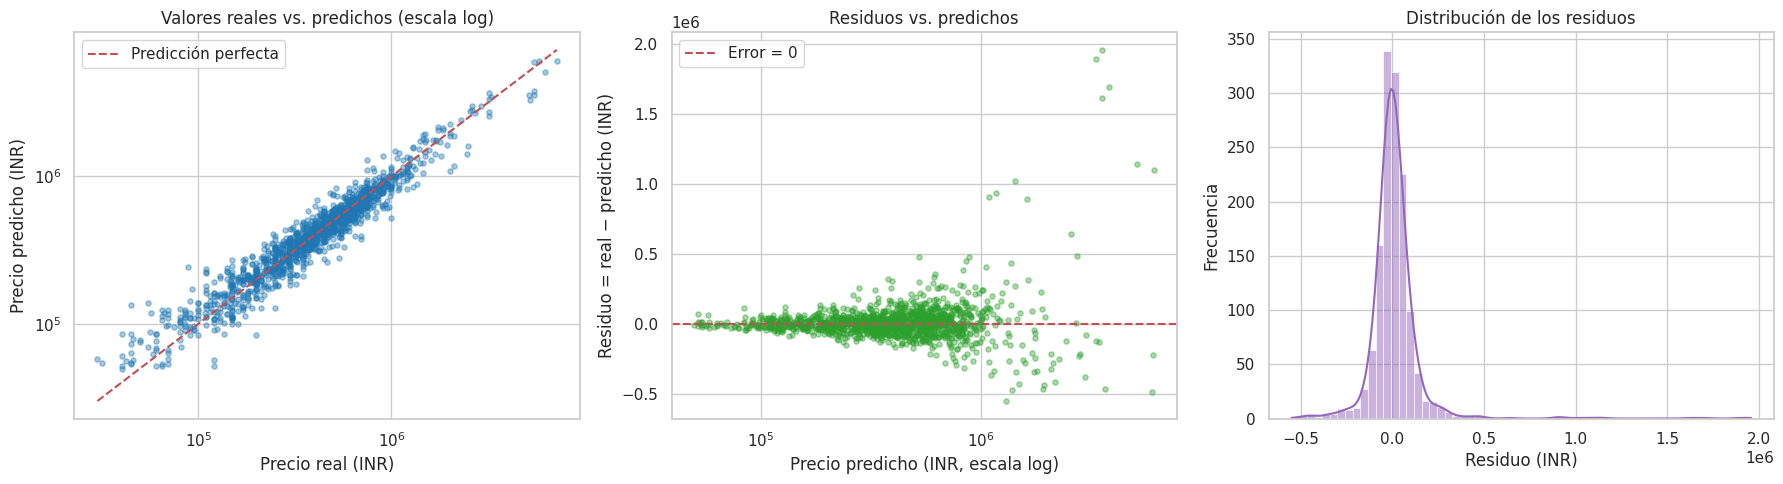

Sesgo medio de los residuos: 10,718 INR | Sobreestima en 50.8 % de los casos


In [30]:
mejor_nombre = res_trad['CV_MAE'].idxmin()      # elegido con validación cruzada (no con el test)
# mejor_nombre = 'Random Forest'     # <- descomenta para forzar otro modelo
mejor = ajustados[mejor_nombre]
y_pred = mejor.predict(X_test)
resid = y_test.values - y_pred
print('Modelo analizado:', mejor_nombre)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(y_test, y_pred, alpha=0.4, s=14, color='tab:blue')
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lim, lim, 'r--', label='Predicción perfecta')
ax[0].set(xscale='log', yscale='log', title='Valores reales vs. predichos (escala log)',
          xlabel='Precio real (INR)', ylabel='Precio predicho (INR)')
ax[0].legend()

ax[1].scatter(y_pred, resid, alpha=0.4, s=14, color='tab:green')
ax[1].axhline(0, color='r', ls='--', label='Error = 0')
ax[1].set(xscale='log', title='Residuos vs. predichos', xlabel='Precio predicho (INR, escala log)',
          ylabel='Residuo = real − predicho (INR)')
ax[1].legend()

sns.histplot(resid, bins=60, kde=True, ax=ax[2], color='tab:purple')
ax[2].set(title='Distribución de los residuos', xlabel='Residuo (INR)', ylabel='Frecuencia')
plt.tight_layout(); plt.show()

print(f'Sesgo medio de los residuos: {resid.mean():,.0f} INR | Sobreestima en {np.mean(resid < 0)*100:.1f} % de los casos')

In [31]:
# ¿Dónde se equivoca más el modelo? Error por cuartil de precio real
cuartil = pd.qcut(y_test.rank(method='first'), 4, labels=['Q1 (más baratos)', 'Q2', 'Q3', 'Q4 (más caros)'])
err = pd.DataFrame({'real': y_test.values, 'pred': y_pred, 'cuartil': cuartil.values})
err['error_abs'] = (err['real'] - err['pred']).abs()
err['error_%']   = err['error_abs'] / err['real'] * 100
tabla_err = err.groupby('cuartil', observed=True).agg(n=('real', 'size'),
                                                       MAE_INR=('error_abs', 'mean'),
                                                       MAPE_pct=('error_%', 'mean')).round(1)
display(tabla_err)

,n,MAE_INR,MAPE_pct
cuartil,,,
Q1 (más baratos),347,"32,834.8000",25.7000
Q2,346,"46,367.5000",14.6000
Q3,346,"64,923.0000",12.7000
Q4 (más caros),346,"154,794.0000",12.7000


✏️ **Interpretación de residuos y errores** (contrastada con las gráficas):
- **Reales vs. predichos:** la nube sigue la diagonal en casi todo el rango → el modelo captura bien la relación general entre características y precio. En precios muy altos (> 2 millones de INR) los puntos se separan de la diagonal: el modelo falla más con los autos de lujo.
- **Residuos vs. predichos:** están centrados en 0 pero con forma de **abanico**: la dispersión **crece con el precio** (heterocedasticidad). Por eso el error en rupias es mucho mayor en autos caros. En los precios altos los residuos extremos son sobre todo **positivos** (precio real > predicho): el modelo tiende a **subestimar** algunos autos de lujo, que son pocos en los datos.
- **Histograma de residuos:** muy concentrado alrededor de 0, con **colas largas**: la mayoría de los autos se estima bien y unos pocos tienen errores grandes.
- **Tabla por cuartiles:** el **error absoluto (MAE) en INR crece con el precio**, mientras que el **error porcentual (MAPE)** es mayor en los autos **más baratos**: un mismo error en rupias pesa más sobre un auto económico (ver cifras de la tabla).

## 4.5 Importancia de variables y comparación con el EDA

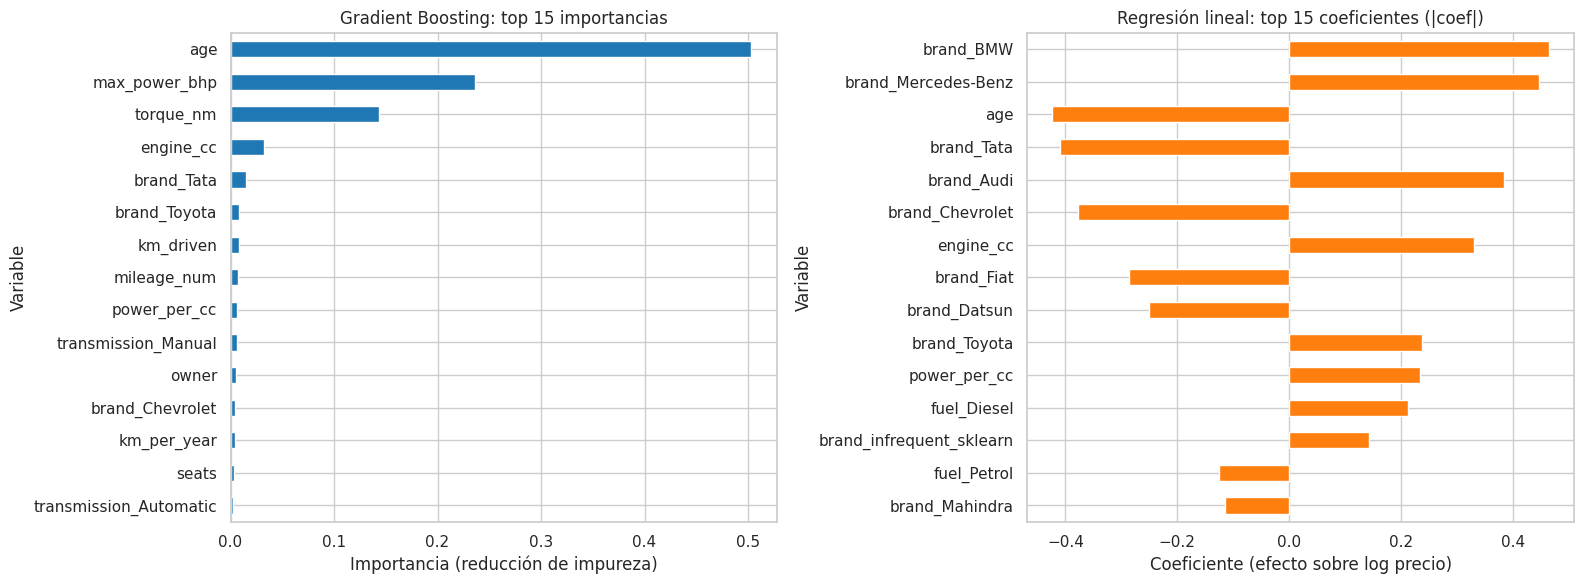

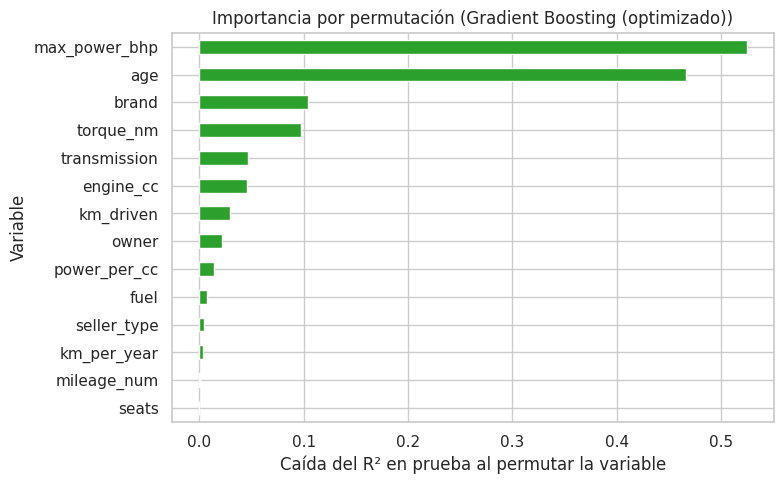

,caída de R²
max_power_bhp,0.5245
age,0.4662
brand,0.1037
torque_nm,0.0975
transmission,0.0465
engine_cc,0.0454
km_driven,0.0297
owner,0.0220
power_per_cc,0.0139
fuel,0.0077



Importancia por permutación de las variables creadas en la sección 2.7:
age            0.4662
brand          0.1037
power_per_cc   0.0139
km_per_year    0.0035


In [32]:
# --- Importancia según Gradient Boosting (feature_importances_) ---
pipe_gb = gb_opt.regressor_
nombres = pipe_gb.named_steps['prep'].get_feature_names_out()
imp = pd.Series(pipe_gb.named_steps['model'].feature_importances_, index=nombres).sort_values(ascending=False)

# --- Coeficientes de la regresión lineal (variables numéricas estandarizadas; el objetivo está en log) ---
pipe_lin = ajustados['Regresión lineal'].regressor_
coef = pd.Series(pipe_lin.named_steps['model'].coef_,
                 index=pipe_lin.named_steps['prep'].get_feature_names_out())

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
imp.head(15).iloc[::-1].plot.barh(ax=ax[0], color='tab:blue')
ax[0].set(title='Gradient Boosting: top 15 importancias', xlabel='Importancia (reducción de impureza)', ylabel='Variable')
coef.reindex(coef.abs().sort_values(ascending=False).head(15).index).iloc[::-1].plot.barh(ax=ax[1], color='tab:orange')
ax[1].set(title='Regresión lineal: top 15 coeficientes (|coef|)', xlabel='Coeficiente (efecto sobre log precio)', ylabel='Variable')
plt.tight_layout(); plt.show()

# --- Importancia por permutación sobre las variables ORIGINALES (más fácil de interpretar) ---
perm = permutation_importance(ajustados[mejor_nombre], X_test, y_test, n_repeats=5,
                              random_state=SEED, scoring='r2', n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
imp_perm.iloc[::-1].plot.barh(color='tab:green')
plt.title(f'Importancia por permutación ({mejor_nombre})')
plt.xlabel('Caída del R² en prueba al permutar la variable'); plt.ylabel('Variable')
plt.tight_layout(); plt.show()
display(imp_perm.round(4).to_frame('caída de R²'))
print('\nImportancia por permutación de las variables creadas en la sección 2.7:')
print(imp_perm.reindex(['age', 'brand', 'power_per_cc', 'km_per_year']).round(4).to_string())

✏️ **Comparación con el EDA** (contrastada con las gráficas y la tabla de permutación):
- **Coincide con el EDA:** las dos variables más asociadas al precio en el EDA —**potencia** (correlación ≈ 0.65 con el log del precio) y **antigüedad** (≈ −0.72)— son, con mucha diferencia, las de mayor importancia por permutación. El **par motor** (`torque_nm`) aparece tercero porque está muy correlacionado con la potencia.
- **Matices:** `engine_cc` y `fuel` tienen importancia casi nula pese a que el EDA mostraba diferencias claras (diésel más caro, motores grandes más caros). Se explica por **redundancia y confusión**: la cilindrada ya está recogida por la potencia y el par, y los diésel son más caros en parte porque son más potentes y más grandes. Una vez conocidas potencia y antigüedad, aportan poca información adicional.
- `transmission`, `km_driven` y `brand` aportan poco pero positivo, de acuerdo con las diferencias vistas en el EDA.
- **Variables creadas:** `age` es decisiva (justifica su construcción). `brand` y `power_per_cc` aportan poco. **`km_per_year` no aportó** (importancia ≈ 0 o negativa en la tabla), así que se podría eliminar sin pérdida: no todas las variables de ingeniería resultan útiles.
- La importancia por impureza (Gradient Boosting) y la de permutación (modelo seleccionado) no coinciden exactamente; la permutación sobre variables originales evita repartir el peso entre las columnas *one-hot* y es más fácil de explicar.

## 🏁 Reto del Bloque 4: selección del modelo sin basarse en una sola métrica
Criterios: (1) exactitud (R², MAE, RMSE); (2) **error relativo** (MAPE, importante porque el costo de equivocarse depende del precio del auto); (3) **generalización** (brecha R² entrenamiento − prueba y estabilidad en CV); (4) **interpretabilidad**.

In [33]:
interpretabilidad = {'Regresión lineal': 'Alta', 'Árbol de decisión': 'Media-alta', 'Random Forest': 'Baja',
                     'Gradient Boosting': 'Baja', 'Gradient Boosting (optimizado)': 'Baja'}
criterios = res_trad[['CV_MAE', 'CV_RMSE', 'CV_R2_media', 'CV_R2_std', 'R2_test', 'MAE', 'RMSE', 'MAPE_%']].copy()
criterios['brecha_R2 (train-test)'] = res_trad['R2_train'] - res_trad['R2_test']
criterios['interpretabilidad'] = pd.Series(interpretabilidad)
display(criterios.round(3))

,CV_MAE,CV_RMSE,CV_R2_media,CV_R2_std,R2_test,MAE,RMSE,MAPE_%,brecha_R2 (train-test),interpretabilidad
Modelo,,,,,,,,,,
Gradient Boosting (optimizado),"77,740.3600","173,759.1920",0.8790,0.0450,0.9260,"74,699.5690","153,346.4860",16.4230,0.0370,Baja
Random Forest,"79,777.6290","184,357.1130",0.8640,0.0430,0.9220,"76,838.9680","157,434.5710",17.1420,0.0400,Baja
Gradient Boosting,"85,371.4300","188,173.7180",0.8600,0.0390,0.9080,"81,279.8700","170,637.8030",17.6460,0.0100,Baja
Regresión lineal,"93,735.7440","177,531.9910",0.8750,0.0290,0.8690,"94,628.2980","204,022.1090",20.2920,0.0160,Alta
Árbol de decisión,"94,410.5710","206,441.4750",0.8320,0.0240,0.8460,"95,145.2580","221,435.1470",20.1610,0.0780,Media-alta


✏️ **Selección del modelo tradicional** — el texto siguiente se genera con las cifras de esta ejecución (celda de abajo).

In [34]:
f = criterios.loc[mejor_nombre]
mediana_train = y_train.median()
orden = res_trad['CV_MAE'].sort_values()
segundo = orden.index[1]
dif_cv = (orden.iloc[1] / orden.iloc[0] - 1) * 100
q_bajo, q_alto = tabla_err.iloc[0], tabla_err.iloc[-1]

if mejor_nombre == 'Regresión lineal':
    item4 = (f"**{interpretabilidad[mejor_nombre].lower()}**: es el modelo más transparente (cada coeficiente tiene una lectura directa) "
             f"y además es el de menor error en validación cruzada, así que no hay que sacrificar interpretabilidad para ganar precisión.")
    decision = "se elige por combinar el menor error de validación con la mayor interpretabilidad; un modelo más complejo no aporta una mejora clara en validación."
else:
    item4 = (f"**{interpretabilidad[mejor_nombre].lower()}** interpretabilidad. La regresión lineal es la más transparente "
             f"(R² test = {criterios.loc['Regresión lineal','R2_test']:.3f}), pero su error de validación es mayor "
             f"(MAE de CV = {criterios.loc['Regresión lineal','CV_MAE']:,.0f} INR frente a {f['CV_MAE']:,.0f} INR). "
             f"La pérdida de transparencia se compensa con `feature_importances_` y la importancia por permutación, que permiten explicar qué variables pesan.")
    decision = ("se prioriza el **rendimiento** (el uso previsto es una estimación automática de precio, donde importa más acertar que explicar "
                "cada coeficiente), manteniendo la explicación a nivel de variables con la importancia por permutación.")

texto_seleccion = f"""
**Modelo seleccionado: {mejor_nombre}.** No se eligió por una sola métrica, sino con cuatro criterios:

1. **Exactitud medida sin mirar el test.** Es el de menor MAE en validación cruzada (**{f['CV_MAE']:,.0f} INR**; RMSE de CV = {f['CV_RMSE']:,.0f} INR; R² de CV = {f['CV_R2_media']:.3f} ± {f['CV_R2_std']:.3f}). El segundo es *{segundo}*, con un MAE de CV {dif_cv:.1f} % mayor: la diferencia entre los mejores es pequeña frente a la variabilidad entre pliegues, así que se desempata con los otros criterios. Ya en el conjunto de prueba (usado una sola vez) obtiene **R² = {f['R2_test']:.3f}, MAE = {f['MAE']:,.0f} INR, RMSE = {f['RMSE']:,.0f} INR y MAPE = {f['MAPE_%']:.1f} %**.
2. **Generalización.** La brecha de R² entre entrenamiento y prueba es **{f['brecha_R2 (train-test)']:.3f}**; una brecha pequeña indica que no memoriza, y la desviación del R² entre pliegues es {f['CV_R2_std']:.3f}.
3. **Costo de los errores.** El MAE equivale a ≈ **{f['MAE'] / mediana_train * 100:.0f} %** del precio mediano ({mediana_train:,.0f} INR): suficiente para *estimar un precio de salida*, pero no para fijar un precio final sin revisión humana. El error depende del segmento: en el cuartil más barato el error porcentual es de {q_bajo['MAPE_pct']:.0f} % (un error pequeño en rupias pesa mucho sobre un auto económico), y en el más caro el error medio sube a {q_alto['MAE_INR']:,.0f} INR (en rupias, un error grande en un auto de lujo).
4. **Interpretabilidad.** {item4}

**Decisión:** {decision}
"""
display(Markdown(texto_seleccion))


**Modelo seleccionado: Gradient Boosting (optimizado).** No se eligió por una sola métrica, sino con cuatro criterios:

1. **Exactitud medida sin mirar el test.** Es el de menor MAE en validación cruzada (**77,740 INR**; RMSE de CV = 173,759 INR; R² de CV = 0.879 ± 0.045). El segundo es *Random Forest*, con un MAE de CV 2.6 % mayor: la diferencia entre los mejores es pequeña frente a la variabilidad entre pliegues, así que se desempata con los otros criterios. Ya en el conjunto de prueba (usado una sola vez) obtiene **R² = 0.926, MAE = 74,700 INR, RMSE = 153,346 INR y MAPE = 16.4 %**.
2. **Generalización.** La brecha de R² entre entrenamiento y prueba es **0.037**; una brecha pequeña indica que no memoriza, y la desviación del R² entre pliegues es 0.045.
3. **Costo de los errores.** El MAE equivale a ≈ **19 %** del precio mediano (400,000 INR): suficiente para *estimar un precio de salida*, pero no para fijar un precio final sin revisión humana. El error depende del segmento: en el cuartil más barato el error porcentual es de 26 % (un error pequeño en rupias pesa mucho sobre un auto económico), y en el más caro el error medio sube a 154,794 INR (en rupias, un error grande en un auto de lujo).
4. **Interpretabilidad.** **baja** interpretabilidad. La regresión lineal es la más transparente (R² test = 0.869), pero su error de validación es mayor (MAE de CV = 93,736 INR frente a 77,740 INR). La pérdida de transparencia se compensa con `feature_importances_` y la importancia por permutación, que permiten explicar qué variables pesan.

**Decisión:** se prioriza el **rendimiento** (el uso previsto es una estimación automática de precio, donde importa más acertar que explicar cada coeficiente), manteniendo la explicación a nivel de variables con la importancia por permutación.


# Bloque 5. Red neuronal artificial (TensorFlow/Keras)

**Diseño:**
- **Mismas variables predictoras y misma división** train/test del Bloque 4.
- **Preprocesamiento:** el mismo `preprocessor` (escalado, imputación y codificación) **ajustado solo con entrenamiento**.
- **Objetivo:** `log(1+precio)` estandarizado con la media y desviación **de entrenamiento**; las predicciones se devuelven a INR para evaluar con las mismas métricas.
- **Arquitectura base:** entrada = n.º de variables tras el preprocesamiento → `Dense(64, ReLU)` → `Dense(32, ReLU)` → `Dense(1, lineal)`. Dos capas ocultas (mínimo exigido) con ReLU: no linealidad simple y estable; el tamaño decreciente (64→32) comprime la información progresivamente; con ~6 000 filas, redes más grandes tienden a sobreajustar. **Salida lineal de 1 neurona** porque es regresión.
- **Pérdida:** MSE (penaliza más los errores grandes, coherente con RMSE) y optimizador **Adam** (tasa de aprendizaje adaptativa, converge bien sin mucho ajuste).
- **Validación:** `validation_split=0.2` sobre el conjunto de entrenamiento; **EarlyStopping** (paciencia 15, restaura los mejores pesos); máximo **200 épocas**.

In [35]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

tf.keras.utils.set_random_seed(SEED)

# Preprocesamiento ajustado SOLO con entrenamiento
prep_nn = clone(preprocessor).fit(X_train)
Xtr = prep_nn.transform(X_train).astype('float32')
Xte = prep_nn.transform(X_test).astype('float32')

# Objetivo en escala log y estandarizado (media/desv. de TRAIN)
ytr_log = np.log1p(y_train.values)
mu, sd = ytr_log.mean(), ytr_log.std()
ytr_s = ((ytr_log - mu) / sd).astype('float32')

print('Entradas de la red (n.º de variables tras el preprocesamiento):', Xtr.shape[1])
print('Xtr:', Xtr.shape, '| Xte:', Xte.shape)

def construir_red(n_entradas, unidades=(64, 32), l2=0.0, dropout=0.0, lr=1e-3):
    m = keras.Sequential([layers.Input(shape=(n_entradas,))])
    for u in unidades:
        m.add(layers.Dense(u, activation='relu',
                           kernel_regularizer=regularizers.l2(l2) if l2 > 0 else None))
        if dropout > 0:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation='linear'))                     # regresión -> salida lineal
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='mse', metrics=['mae'])
    return m

def entrenar(batch_size=32, **kw):
    tf.keras.utils.set_random_seed(SEED)
    modelo = construir_red(Xtr.shape[1], **kw)
    es = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    hist = modelo.fit(Xtr, ytr_s, validation_split=0.2, epochs=200, batch_size=batch_size,
                      callbacks=[es], verbose=0)
    return modelo, hist

def pred_inr(modelo, Xm):
    return np.expm1(modelo.predict(Xm, verbose=0).ravel() * sd + mu)

modelo_base = construir_red(Xtr.shape[1])
modelo_base.summary()

Entradas de la red (n.º de variables tras el preprocesamiento): 37
Xtr: (5539, 37) | Xte: (1385, 37)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,545 (17.75 KB)

 Trainable params: 4,545 (17.75 KB)

 Non-trainable params: 0 (0.00 B)

## 5.1 Entrenamiento de la red base y curvas de aprendizaje

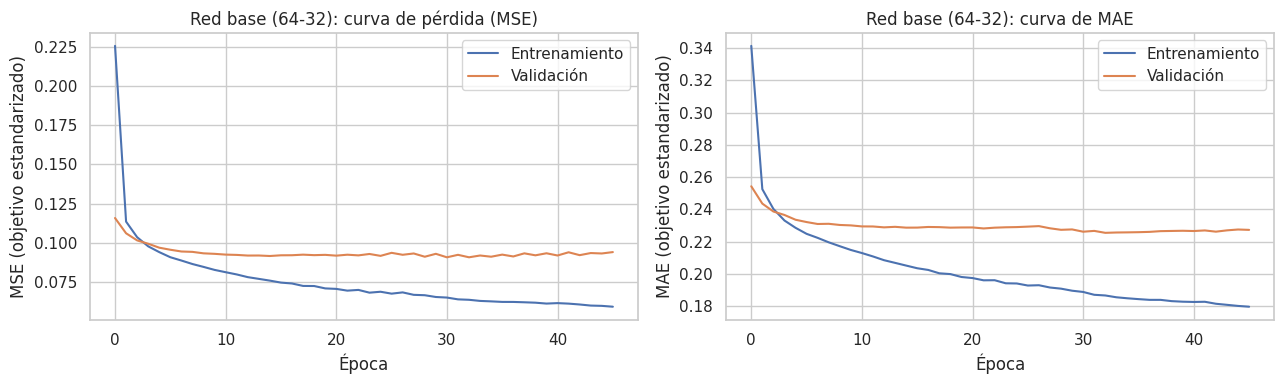

R2_train                      0.9140
CV_R2_media                      NaN
CV_R2_std                        NaN
CV_MAE                           NaN
CV_RMSE                          NaN
R2_test                       0.8800
MAE                      84,960.3770
RMSE                    194,979.4330
MAPE_%                       18.2030
épocas                       46.0000
val_mae_min (estand.)         0.2250


In [36]:
def graficar_curvas(hist, titulo):
    h = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(h['loss'], label='Entrenamiento'); ax[0].plot(h['val_loss'], label='Validación')
    ax[0].set(title=f'{titulo}: curva de pérdida (MSE)', xlabel='Época', ylabel='MSE (objetivo estandarizado)')
    ax[0].legend()
    ax[1].plot(h['mae'], label='Entrenamiento'); ax[1].plot(h['val_mae'], label='Validación')
    ax[1].set(title=f'{titulo}: curva de MAE', xlabel='Época', ylabel='MAE (objetivo estandarizado)')
    ax[1].legend()
    plt.tight_layout(); plt.show()

resultados_nn, historias = {}, {}

def registrar(nombre, modelo, hist):
    historias[nombre] = hist
    met = metricas(y_test, pred_inr(modelo, Xte))
    resultados_nn[nombre] = {
        'R2_train': r2_score(y_train, pred_inr(modelo, Xtr)),
        'CV_R2_media': np.nan, 'CV_R2_std': np.nan, 'CV_MAE': np.nan, 'CV_RMSE': np.nan,
        'R2_test': met['R2'], 'MAE': met['MAE'], 'RMSE': met['RMSE'], 'MAPE_%': met['MAPE_%'],
        'épocas': len(hist.history['loss']),
        'val_mae_min (estand.)': min(hist.history['val_mae'])}

modelo_nn0, hist0 = entrenar(unidades=(64, 32))
registrar('Red base (64-32)', modelo_nn0, hist0)
graficar_curvas(hist0, 'Red base (64-32)')
print(pd.Series(resultados_nn['Red base (64-32)']).round(3).to_string())

## 5.2 Experimentos de mejora (≥ 2)
1. **Regularización:** L2 (`1e-3`) + `Dropout(0.2)` para reducir el sobreajuste.
2. **Arquitectura y optimización:** red más profunda (128-64-32), tasa de aprendizaje menor (`5e-4`) y lote de 64.

**Criterio de selección:** se elige por el **MAE de validación** (no por el de prueba) para no "mirar" el conjunto de prueba al decidir; el MAE se usa en vez de la pérdida porque la pérdida de los modelos con L2 incluye el término de penalización y no es comparable.

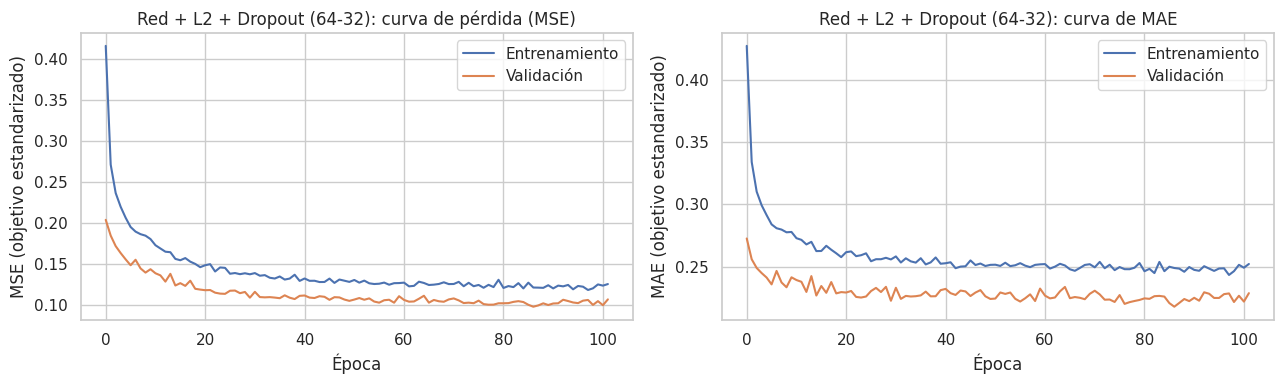

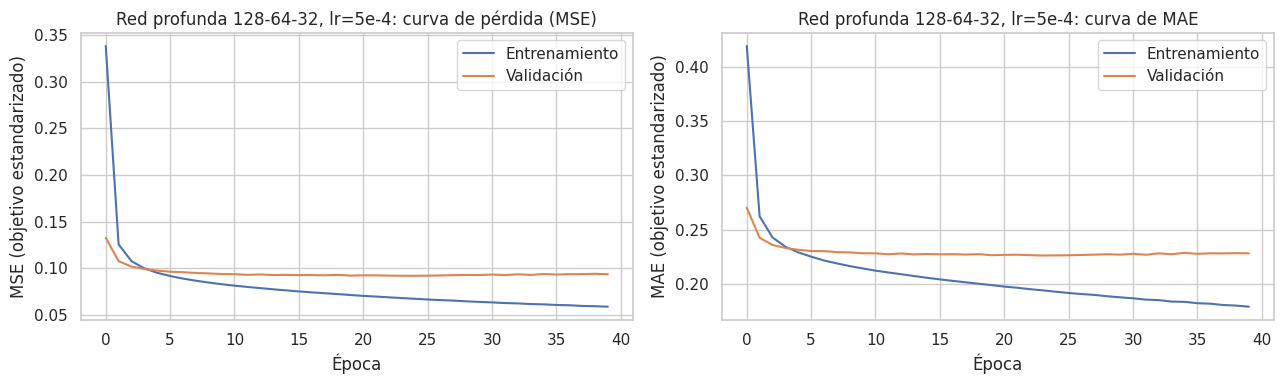

,R2_train,CV_R2_media,CV_R2_std,CV_MAE,CV_RMSE,R2_test,MAE,RMSE,MAPE_%,épocas,val_mae_min (estand.)
Red base (64-32),0.9140,NaN,NaN,NaN,NaN,0.8800,"84,960.3770","194,979.4330",18.2030,46.0000,0.2250
Red + L2 + Dropout (64-32),0.8720,NaN,NaN,NaN,NaN,0.8620,"85,009.6230","209,359.4900",17.9510,102.0000,0.2180
"Red profunda 128-64-32, lr=5e-4",0.9350,NaN,NaN,NaN,NaN,0.9030,"83,816.4280","175,703.8840",18.8270,40.0000,0.2260


➡ Mejor red según MAE de validación: Red + L2 + Dropout (64-32)


In [37]:
experimentos = {
    'Red + L2 + Dropout (64-32)':       dict(unidades=(64, 32),      l2=1e-3, dropout=0.2),
    'Red profunda 128-64-32, lr=5e-4':  dict(unidades=(128, 64, 32), lr=5e-4, batch_size=64),
}
modelos_nn = {'Red base (64-32)': modelo_nn0}
for nombre, kw in experimentos.items():
    m, h = entrenar(**kw)
    modelos_nn[nombre] = m
    registrar(nombre, m, h)
    graficar_curvas(h, nombre)

res_nn = pd.DataFrame(resultados_nn).T
display(res_nn.round(3))
mejor_red = res_nn['val_mae_min (estand.)'].astype(float).idxmin()
print(f'➡ Mejor red según MAE de validación: {mejor_red}')

## 5.3 Tabla final comparativa: modelos tradicionales + red neuronal

,R2_train,CV_R2_media,CV_R2_std,CV_MAE,CV_RMSE,R2_test,MAE,RMSE,MAPE_%,brecha_R2 (train-test)
Gradient Boosting (optimizado),0.9620,0.8790,0.0450,"77,740.3600","173,759.1920",0.9260,"74,699.5690","153,346.4860",16.4230,0.0370
Random Forest,0.9620,0.8640,0.0430,"79,777.6290","184,357.1130",0.9220,"76,838.9680","157,434.5710",17.1420,0.0400
Gradient Boosting,0.9180,0.8600,0.0390,"85,371.4300","188,173.7180",0.9080,"81,279.8700","170,637.8030",17.6460,0.0100
"Red profunda 128-64-32, lr=5e-4",0.9350,NaN,NaN,NaN,NaN,0.9030,"83,816.4280","175,703.8840",18.8270,0.0320
Red base (64-32),0.9140,NaN,NaN,NaN,NaN,0.8800,"84,960.3770","194,979.4330",18.2030,0.0340
Regresión lineal,0.8850,0.8750,0.0290,"93,735.7440","177,531.9910",0.8690,"94,628.2980","204,022.1090",20.2920,0.0160
Red + L2 + Dropout (64-32),0.8720,NaN,NaN,NaN,NaN,0.8620,"85,009.6230","209,359.4900",17.9510,0.0100
Árbol de decisión,0.9240,0.8320,0.0240,"94,410.5710","206,441.4750",0.8460,"95,145.2580","221,435.1470",20.1610,0.0780


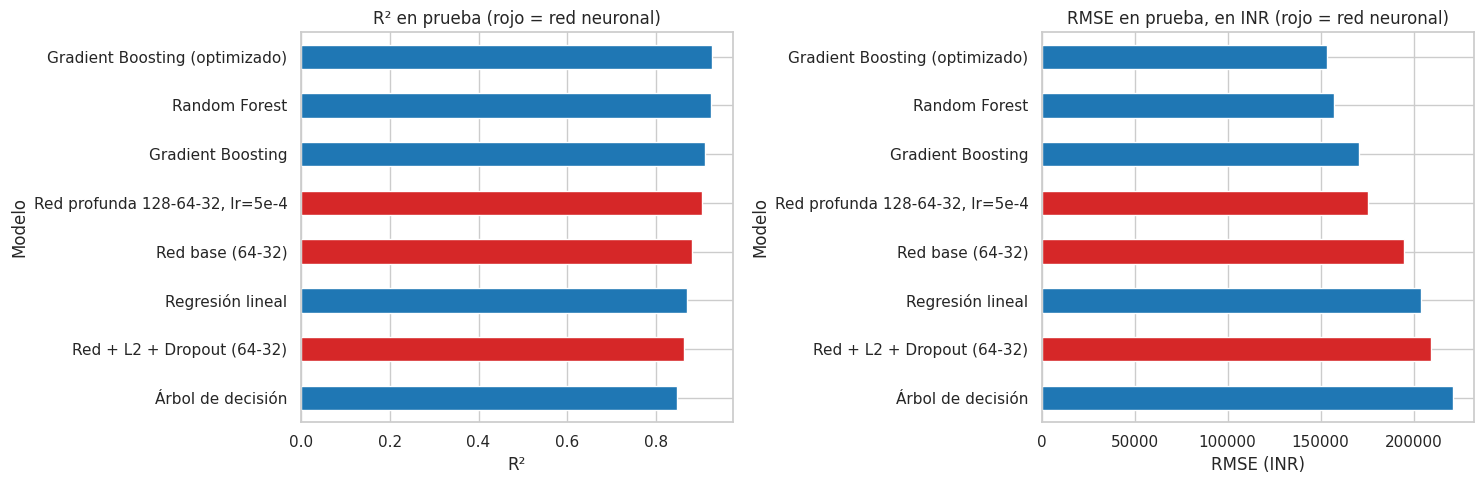

In [38]:
cols_final = ['R2_train', 'CV_R2_media', 'CV_R2_std', 'CV_MAE', 'CV_RMSE', 'R2_test', 'MAE', 'RMSE', 'MAPE_%']
tabla_final = pd.concat([res_base[cols_final], res_nn[cols_final].astype(float)])
tabla_final['brecha_R2 (train-test)'] = tabla_final['R2_train'] - tabla_final['R2_test']
tabla_final = tabla_final.sort_values('RMSE')
display(tabla_final.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
colores = ['tab:red' if 'Red' in n else 'tab:blue' for n in tabla_final.index]
tabla_final['R2_test'].iloc[::-1].plot.barh(ax=ax[0], color=colores[::-1])
ax[0].set(title='R² en prueba (rojo = red neuronal)', xlabel='R²', ylabel='Modelo')
tabla_final['RMSE'].iloc[::-1].plot.barh(ax=ax[1], color=colores[::-1])
ax[1].set(title='RMSE en prueba, en INR (rojo = red neuronal)', xlabel='RMSE (INR)', ylabel='Modelo')
plt.tight_layout(); plt.show()

## 🏁 Reto del Bloque 5: sobreajuste/subajuste y ¿vale la pena la red?
El diagnóstico se genera con las cifras y las curvas de esta ejecución (celda de abajo).

In [39]:
base_n, reg_n, prof_n = 'Red base (64-32)', 'Red + L2 + Dropout (64-32)', 'Red profunda 128-64-32, lr=5e-4'
n_ep     = lambda n: len(historias[n].history['loss'])
mejor_ep = lambda n: int(np.argmin(historias[n].history['val_loss'])) + 1
brecha   = lambda n: res_nn.loc[n, 'R2_train'] - res_nn.loc[n, 'R2_test']
rmse_n   = lambda n: res_nn.loc[n, 'RMSE']

rmse_trad, r2_trad = res_trad.loc[mejor_nombre, 'RMSE'], res_trad.loc[mejor_nombre, 'R2_test']
rmse_red,  r2_red  = res_nn.loc[mejor_red, 'RMSE'],      res_nn.loc[mejor_red, 'R2_test']
dif_rmse = (rmse_red / rmse_trad - 1) * 100

if res_nn.loc[reg_n, 'R2_test'] < res_nn.loc[base_n, 'R2_test']:
    nota_reg = 'La regularización fue demasiado fuerte para estos datos: el modelo pasó a **subajustar** (se ajusta peor incluso al entrenamiento), sobre todo en los autos caros.'
elif brecha(reg_n) < brecha(base_n):
    nota_reg = 'La regularización ayudó a generalizar.'
else:
    nota_reg = 'La regularización no aportó una mejora clara.'
if rmse_n(prof_n) < rmse_n(base_n):
    nota_prof = 'la mayor profundidad sí ayudó, aunque con más costo de cómputo.'
else:
    nota_prof = 'con la misma información de entrada, añadir capas **no** aporta precisión, solo complejidad.'

texto_reto5 = f"""
**Diagnóstico con las curvas y la tabla** (cifras de esta ejecución):

- **Sobreajuste en la red base (64-32).** La pérdida de entrenamiento sigue bajando mientras la de validación se aplana: las curvas se separan. R² en entrenamiento = {res_nn.loc[base_n,'R2_train']:.3f} frente a {res_nn.loc[base_n,'R2_test']:.3f} en prueba (brecha {brecha(base_n):.3f}). El **EarlyStopping** detuvo el entrenamiento en la época {n_ep(base_n)} y restauró los pesos de la época {mejor_ep(base_n)}, evitando entrenar de más.
- **Experimento 1 (L2 + Dropout):** {'redujo' if brecha(reg_n) < brecha(base_n) else 'no redujo'} la brecha (de {brecha(base_n):.3f} a {brecha(reg_n):.3f}), pero el R² de entrenamiento {'bajó' if res_nn.loc[reg_n,'R2_train'] < res_nn.loc[base_n,'R2_train'] else 'no bajó'} (de {res_nn.loc[base_n,'R2_train']:.3f} a {res_nn.loc[reg_n,'R2_train']:.3f}) y el RMSE en prueba {'mejoró' if rmse_n(reg_n) < rmse_n(base_n) else 'empeoró'} (de {rmse_n(base_n):,.0f} a {rmse_n(reg_n):,.0f} INR). {nota_reg} En sus curvas la validación queda por debajo del entrenamiento porque Dropout y L2 solo actúan al entrenar.
- **Experimento 2 (red más profunda, lr = 5e-4, lote 64):** el RMSE en prueba {'mejoró' if rmse_n(prof_n) < rmse_n(base_n) else 'no mejoró'} ({rmse_n(base_n):,.0f} → {rmse_n(prof_n):,.0f} INR); {nota_prof}
- **Selección sin mirar el test:** se eligió **{mejor_red}** por menor MAE de validación; su RMSE en prueba es {rmse_red:,.0f} INR (R² = {r2_red:.3f}). Nota: el MAE y el RMSE pueden no coincidir, porque el RMSE castiga mucho más los errores en los autos caros.
- **¿Justifica la red su complejidad?** Frente a {mejor_nombre} (R² = {r2_trad:.3f}, RMSE = {rmse_trad:,.0f} INR), la red tiene un RMSE {abs(dif_rmse):.1f} % {'mayor' if dif_rmse > 0 else 'menor'}. {'**No se justifica**: no supera al modelo tradicional y además es más costosa de entrenar y más difícil de explicar. En datos tabulares de ~7 000 filas los ensambles de árboles suelen igualar o superar a una red densa.' if dif_rmse >= 0 else '**Sí aporta una mejora**, pero hay que contrastarla con su mayor costo de cómputo y menor interpretabilidad antes de adoptarla.'}
"""
display(Markdown(texto_reto5))


**Diagnóstico con las curvas y la tabla** (cifras de esta ejecución):

- **Sobreajuste en la red base (64-32).** La pérdida de entrenamiento sigue bajando mientras la de validación se aplana: las curvas se separan. R² en entrenamiento = 0.914 frente a 0.880 en prueba (brecha 0.034). El **EarlyStopping** detuvo el entrenamiento en la época 46 y restauró los pesos de la época 31, evitando entrenar de más.
- **Experimento 1 (L2 + Dropout):** redujo la brecha (de 0.034 a 0.010), pero el R² de entrenamiento bajó (de 0.914 a 0.872) y el RMSE en prueba empeoró (de 194,979 a 209,359 INR). La regularización fue demasiado fuerte para estos datos: el modelo pasó a **subajustar** (se ajusta peor incluso al entrenamiento), sobre todo en los autos caros. En sus curvas la validación queda por debajo del entrenamiento porque Dropout y L2 solo actúan al entrenar.
- **Experimento 2 (red más profunda, lr = 5e-4, lote 64):** el RMSE en prueba mejoró (194,979 → 175,704 INR); la mayor profundidad sí ayudó, aunque con más costo de cómputo.
- **Selección sin mirar el test:** se eligió **Red + L2 + Dropout (64-32)** por menor MAE de validación; su RMSE en prueba es 209,359 INR (R² = 0.862). Nota: el MAE y el RMSE pueden no coincidir, porque el RMSE castiga mucho más los errores en los autos caros.
- **¿Justifica la red su complejidad?** Frente a Gradient Boosting (optimizado) (R² = 0.926, RMSE = 153,346 INR), la red tiene un RMSE 36.5 % mayor. **No se justifica**: no supera al modelo tradicional y además es más costosa de entrenar y más difícil de explicar. En datos tabulares de ~7 000 filas los ensambles de árboles suelen igualar o superar a una red densa.


# Pregunta adicional de nivel alto (+10 puntos) — Escenario A (regresión)

> *Suponga que su modelo obtiene un R² de 0.92 en entrenamiento y de 0.55 en prueba.*

Primero se **reproduce el fenómeno con nuestros datos**: un árbol de decisión sin límite de profundidad memoriza el entrenamiento; al limitar la profundidad (regularizar) el R² de validación mejora.

,max_depth,R2_train,R2_CV_media,R2_CV_std
0,2,0.2940,0.2990,0.0380
1,4,0.6930,0.6820,0.0580
2,6,0.8490,0.7720,0.0600
3,8,0.9330,0.8020,0.0420
4,12,0.9820,0.7940,0.0810
5,20,0.9990,0.8190,0.0530
6,sin límite,0.9990,0.8120,0.0570


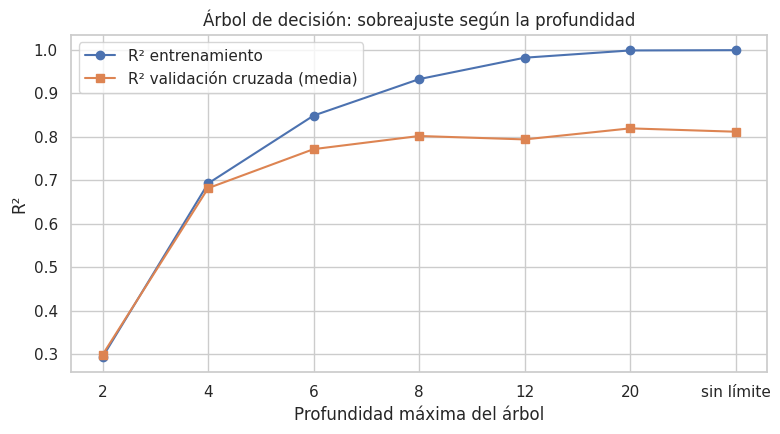

Línea base (predecir siempre la media): R² = -0.058 | MAE = 286,246 INR
Mejor modelo (Gradient Boosting (optimizado)): R² = 0.926 | MAE = 74,700 INR


In [40]:
profundidades = [2, 4, 6, 8, 12, 20, None]
filas = []
for d in profundidades:
    m = armar(DecisionTreeRegressor(max_depth=d, random_state=SEED))
    cv = cross_val_score(m, X_train, y_train, cv=kf, scoring='r2')
    m.fit(X_train, y_train)
    filas.append({'max_depth': 'sin límite' if d is None else d,
                  'R2_train': r2_score(y_train, m.predict(X_train)),
                  'R2_CV_media': cv.mean(), 'R2_CV_std': cv.std()})
curva = pd.DataFrame(filas)
display(curva.round(3))

x = range(len(curva))
plt.figure(figsize=(8, 4.5))
plt.plot(x, curva['R2_train'], marker='o', label='R² entrenamiento')
plt.plot(x, curva['R2_CV_media'], marker='s', label='R² validación cruzada (media)')
plt.xticks(x, curva['max_depth'].astype(str))
plt.title('Árbol de decisión: sobreajuste según la profundidad')
plt.xlabel('Profundidad máxima del árbol'); plt.ylabel('R²'); plt.legend()
plt.tight_layout(); plt.show()

# Línea base: ¿qué tan útil es el modelo frente a "predecir siempre la media"?
base_m = armar(DummyRegressor(strategy='mean')).fit(X_train, y_train)
met_base = metricas(y_test, base_m.predict(X_test))
print(f'Línea base (predecir siempre la media): R² = {met_base["R2"]:.3f} | MAE = {met_base["MAE"]:,.0f} INR')
print(f'Mejor modelo ({mejor_nombre}): R² = {res_trad.loc[mejor_nombre, "R2_test"]:.3f} | MAE = {res_trad.loc[mejor_nombre, "MAE"]:,.0f} INR')

### Respuestas

**1. ¿Qué problema evidencian estos resultados y cómo lo diagnosticaría con las curvas y la validación cruzada?**
Un R² de 0.92 en entrenamiento frente a 0.55 en prueba es **sobreajuste (alta varianza)**: el modelo aprendió el ruido y las particularidades del entrenamiento y no generaliza. Diagnóstico:
- **Curva de aprendizaje / de complejidad:** si el R² de entrenamiento es alto y el de validación mucho menor (como en la gráfica del árbol sin límite de profundidad), hay una **brecha grande**; la pérdida de entrenamiento baja mientras la de validación se estanca o sube.
- **Validación cruzada k = 5:** un R² medio de CV cercano al del test (≈ 0.55) y muy inferior al de entrenamiento confirma que no es mala suerte de una división; una **desviación estándar alta** entre pliegues indica además inestabilidad.
- Si **ambos** R² fueran bajos y parecidos, el problema sería **subajuste (sesgo)**, no sobreajuste.

**2. ¿Es suficiente el R² para decidir si el modelo es útil? ¿Qué otras métricas y gráficos analizaría?**
**No.** El R² es adimensional, no dice cuánto se equivoca el modelo en unidades reales, puede ser alto con errores inaceptables y depende de la varianza de los datos. Hay que mirar:
- **MAE y RMSE** en INR (y **MAPE**, el error porcentual) y compararlos con el costo real del error en el negocio.
- **Comparación con una línea base** (predecir la media), como en la celda anterior.
- **Residuos**: gráfico de residuos vs. predichos (¿heterocedasticidad?, ¿sesgo?), histograma de residuos, **valores reales vs. predichos**, y el **error por segmentos** (p. ej. por cuartil de precio) para detectar dónde falla.
Un R² de 0.55 podría ser útil para una estimación aproximada o inútil para fijar precios finales; depende de la tolerancia al error.

**3. ¿Qué técnicas aplicaría para mejorar la generalización?**
- **Regularización:** Ridge/Lasso en el modelo lineal; limitar `max_depth`, aumentar `min_samples_leaf` o usar menos variables por división en árboles/Random Forest; **L2, Dropout y EarlyStopping** en la red neuronal.
- **Simplificar el modelo** o **seleccionar variables** (quitar ruido y variables redundantes/colineales).
- **Más datos** o aumentar su calidad (limpiar duplicados y errores).
- **Ensambles** (Random Forest, Gradient Boosting con `learning_rate` bajo) que reducen la varianza, y **ajuste de hiperparámetros con validación cruzada**.

**4. ¿Qué riesgos tiene ajustar el modelo repetidamente mirando el conjunto de prueba y cómo los evitaría?**
Cada vez que se ajusta algo "porque mejora en test", el conjunto de prueba **deja de ser independiente**: se le filtra información (fuga indirecta) y la métrica final queda **optimista** (sobreajuste al conjunto de prueba): el rendimiento real en datos nuevos será peor. Cómo evitarlo:
- Ajustar hiperparámetros **solo con validación cruzada** (o un conjunto de validación) dentro del entrenamiento, como se hizo con `GridSearchCV`.
- Usar el conjunto de prueba **una única vez**, al final, para reportar.
- Para comparar muchos modelos de forma rigurosa: **validación cruzada anidada** o reservar un conjunto de **validación final** aparte; y, idealmente, confirmar con datos nuevos reales.

# Bloque 6. Informe ejecutivo y conclusiones

Resumen automático de las cifras clave (para redactar el informe sin errores de transcripción):

In [41]:
mejor_global = tabla_final['RMSE'].idxmin()
mejor_trad   = mejor_nombre                      # elegido con validación cruzada
print(f'Registros usados: {len(df4):,} (originales: {len(df_raw):,}; duplicados eliminados: {len(df_raw)-len(df1):,})')
print(f'Mejor modelo global en prueba (menor RMSE, solo informativo): {mejor_global}')
print(tabla_final.loc[mejor_global, ['R2_test', 'MAE', 'RMSE', 'MAPE_%']].round(3).to_string())
print(f'\nMejor modelo tradicional: {mejor_trad}')
print(res_trad.loc[mejor_trad, ['R2_test', 'MAE', 'RMSE', 'MAPE_%']].round(3).to_string())
print(f'\nMejor red neuronal (por MAE de validación): {mejor_red}')
print(res_nn.loc[mejor_red, ['R2_test', 'MAE', 'RMSE', 'MAPE_%']].astype(float).round(3).to_string())
print('\nError por cuartil de precio (mejor modelo tradicional):')
display(tabla_err)
print('Top 5 variables por permutación:', list(imp_perm.head(5).index))
print(f'Mediana del precio: {df4["selling_price"].median():,.0f} INR')

Registros usados: 6,924 (originales: 8,128; duplicados eliminados: 1,202)
Mejor modelo global en prueba (menor RMSE, solo informativo): Gradient Boosting (optimizado)
R2_test         0.9260
MAE        74,699.5690
RMSE      153,346.4860
MAPE_%         16.4230

Mejor modelo tradicional: Gradient Boosting (optimizado)
R2_test         0.9260
MAE        74,699.5690
RMSE      153,346.4860
MAPE_%         16.4230

Mejor red neuronal (por MAE de validación): Red + L2 + Dropout (64-32)
R2_test         0.8620
MAE        85,009.6230
RMSE      209,359.4900
MAPE_%         17.9510

Error por cuartil de precio (mejor modelo tradicional):


,n,MAE_INR,MAPE_pct
cuartil,,,
Q1 (más baratos),347,"32,834.8000",25.7000
Q2,346,"46,367.5000",14.6000
Q3,346,"64,923.0000",12.7000
Q4 (más caros),346,"154,794.0000",12.7000


Top 5 variables por permutación: ['max_power_bhp', 'age', 'brand', 'torque_nm', 'transmission']
Mediana del precio: 400,000 INR


## Informe ejecutivo
La celda de abajo redacta el informe con las cifras de tu ejecución

In [42]:
nombres_es = {'max_power_bhp': 'la potencia del motor', 'age': 'la antigüedad del auto', 'torque_nm': 'la fuerza del motor (par motor)',
              'transmission': 'el tipo de transmisión', 'km_driven': 'el kilometraje', 'brand': 'la marca',
              'engine_cc': 'la cilindrada', 'power_per_cc': 'la potencia por cilindrada', 'mileage_num': 'el rendimiento de combustible',
              'owner': 'el número de dueños previos', 'fuel': 'el combustible', 'seller_type': 'el tipo de vendedor', 'seats': 'el número de asientos'}
top3 = [nombres_es.get(v, v) for v in imp_perm.index[:3]]

n_raw, n_dup, n_final = len(df_raw), len(df_raw) - len(df1), len(df4)
n_km = len(df2) - len(df3)
n_gas = int(eda['fuel'].isin(['CNG', 'LPG']).sum())
f_mej = criterios.loc[mejor_nombre]
q_bajo, q_alto = tabla_err.iloc[0], tabla_err.iloc[-1]
r2_nn, mae_nn = res_nn.loc[mejor_red, 'R2_test'], res_nn.loc[mejor_red, 'MAE']
nn_gana = res_nn.loc[mejor_red, 'RMSE'] < res_trad.loc[mejor_nombre, 'RMSE']

informe = f"""
**1. El problema y lo que muestran los datos.** La plataforma de autos usados quiere ayudar a vendedores y compradores a fijar y evaluar precios con criterio y no por intuición. Para lograrlo se analizaron {n_final:,} anuncios de CarDekho (India), tras retirar {n_dup:,} anuncios repetidos ({n_dup / n_raw * 100:.0f} % del total) y {n_km} con kilometrajes imposibles. El precio típico (mediana) es de {df4['selling_price'].median():,.0f} rupias, pero existe una cola de autos de lujo que llega a {df4['selling_price'].max():,.0f}. Lo que más se asocia al precio es {top3[0]}, {top3[1]} y {top3[2]}: los autos más viejos y con más uso valen menos, y los más potentes valen más. Un auto automático cuesta, en mediana, unas {med_a / med_m:.1f} veces lo que uno manual.

**2. El mejor modelo.** Se compararon cuatro modelos tradicionales y una red neuronal. El elegido fue **{mejor_nombre}**: en autos que nunca vio explica alrededor del {f_mej['R2_test'] * 100:.0f} % de la variación de los precios (R² = {f_mej['R2_test']:.2f}) y se equivoca en promedio por {f_mej['MAE']:,.0f} rupias, aproximadamente {f_mej['MAE'] / df4['selling_price'].median() * 100:.0f} % del precio típico. En la validación cruzada obtuvo R² = {f_mej['CV_R2_media']:.2f} ± {f_mej['CV_R2_std']:.2f}, un desempeño razonablemente estable que varía según los autos de lujo que caigan en cada partición. La red neuronal ({mejor_red}) obtuvo R² = {r2_nn:.2f} y un error medio de {mae_nn:,.0f} rupias: {'superó' if nn_gana else 'no superó'} al mejor modelo tradicional, con mayor complejidad y menor facilidad de explicar; por eso {'conviene evaluarla con más datos antes de adoptarla' if nn_gana else 'no se justifica su uso frente al modelo tradicional'}.

**3. Errores y costo en la vida real.** El modelo se equivoca más en rupias en los autos caros (error medio de {q_alto['MAE_INR']:,.0f} rupias en el cuarto más caro) y más en proporción en los baratos ({q_bajo['MAPE_pct']:.0f} % de error en el cuarto más económico). En los autos de lujo suele quedarse corto, porque hay pocos en los datos. En la práctica: si el modelo sobreestima, el vendedor publica caro y tarda más en vender; si subestima, pierde dinero o el comprador paga menos de lo justo. Por eso sirve como referencia de apoyo, no como precio final automático.

**4. Limitaciones de los datos.** Provienen de un solo sitio web de India y llegan hasta {REF_YEAR}, por lo que no representan otros mercados ni la situación actual. Una parte importante estaba duplicada y cerca de {sin_ficha.mean() * 100:.0f} % de los anuncios no traía ficha técnica, que hubo que estimar. Faltan datos clave: estado mecánico y estético, ubicación, accidentes y equipamiento. Hay muy pocos autos a gas (solo {n_gas}) y de lujo, así que allí las predicciones son menos confiables.

**5. Recomendaciones y trabajo futuro.** (1) Usar el modelo para dar un rango de precio y no un valor único. (2) Mostrar al usuario cuánta incertidumbre tiene cada estimación. (3) Incorporar estado del auto, ubicación y datos recientes. (4) Reentrenar cada cierto tiempo, porque los precios cambian. (5) Probar modelos separados para autos económicos y de lujo, donde el error es mayor.

**6. Consideraciones éticas.** Aunque no se usan datos personales de los vendedores, hay que proteger la privacidad y no publicar información identificable. Un modelo entrenado con un solo mercado puede perjudicar a marcas o segmentos con pocos datos, así que conviene vigilar ese sesgo. Debe presentarse siempre como una estimación y no como una tasación oficial, con revisión humana en las decisiones de alto valor.
"""
n_palabras = len(informe.replace('*', '').split())
print(f'Palabras del informe: {n_palabras}  ->  {"OK (400–600)" if 400 <= n_palabras <= 600 else "FUERA DE RANGO: ajusta el texto"}')
display(Markdown(informe))

Palabras del informe: 550  ->  OK (400–600)



**1. El problema y lo que muestran los datos.** La plataforma de autos usados quiere ayudar a vendedores y compradores a fijar y evaluar precios con criterio y no por intuición. Para lograrlo se analizaron 6,924 anuncios de CarDekho (India), tras retirar 1,202 anuncios repetidos (15 % del total) y 2 con kilometrajes imposibles. El precio típico (mediana) es de 400,000 rupias, pero existe una cola de autos de lujo que llega a 10,000,000. Lo que más se asocia al precio es la potencia del motor, la antigüedad del auto y la marca: los autos más viejos y con más uso valen menos, y los más potentes valen más. Un auto automático cuesta, en mediana, unas 2.2 veces lo que uno manual.

**2. El mejor modelo.** Se compararon cuatro modelos tradicionales y una red neuronal. El elegido fue **Gradient Boosting (optimizado)**: en autos que nunca vio explica alrededor del 93 % de la variación de los precios (R² = 0.93) y se equivoca en promedio por 74,700 rupias, aproximadamente 19 % del precio típico. En la validación cruzada obtuvo R² = 0.88 ± 0.04, un desempeño razonablemente estable que varía según los autos de lujo que caigan en cada partición. La red neuronal (Red + L2 + Dropout (64-32)) obtuvo R² = 0.86 y un error medio de 85,010 rupias: no superó al mejor modelo tradicional, con mayor complejidad y menor facilidad de explicar; por eso no se justifica su uso frente al modelo tradicional.

**3. Errores y costo en la vida real.** El modelo se equivoca más en rupias en los autos caros (error medio de 154,794 rupias en el cuarto más caro) y más en proporción en los baratos (26 % de error en el cuarto más económico). En los autos de lujo suele quedarse corto, porque hay pocos en los datos. En la práctica: si el modelo sobreestima, el vendedor publica caro y tarda más en vender; si subestima, pierde dinero o el comprador paga menos de lo justo. Por eso sirve como referencia de apoyo, no como precio final automático.

**4. Limitaciones de los datos.** Provienen de un solo sitio web de India y llegan hasta 2020, por lo que no representan otros mercados ni la situación actual. Una parte importante estaba duplicada y cerca de 3 % de los anuncios no traía ficha técnica, que hubo que estimar. Faltan datos clave: estado mecánico y estético, ubicación, accidentes y equipamiento. Hay muy pocos autos a gas (solo 94) y de lujo, así que allí las predicciones son menos confiables.

**5. Recomendaciones y trabajo futuro.** (1) Usar el modelo para dar un rango de precio y no un valor único. (2) Mostrar al usuario cuánta incertidumbre tiene cada estimación. (3) Incorporar estado del auto, ubicación y datos recientes. (4) Reentrenar cada cierto tiempo, porque los precios cambian. (5) Probar modelos separados para autos económicos y de lujo, donde el error es mayor.

**6. Consideraciones éticas.** Aunque no se usan datos personales de los vendedores, hay que proteger la privacidad y no publicar información identificable. Un modelo entrenado con un solo mercado puede perjudicar a marcas o segmentos con pocos datos, así que conviene vigilar ese sesgo. Debe presentarse siempre como una estimación y no como una tasación oficial, con revisión humana en las decisiones de alto valor.


# Declaración de uso de herramientas de IA

- **Herramienta usada:** Claude.
- **Para qué se usó:** apoyo para estructurar el notebook según los bloques de la guía, proponer el código base de los bloques 1 a 5 y redactar borradores de las interpretaciones y del informe.
- **Qué hice yo:** elegí el dataset y el problema, ejecuté todo el notebook en Google Colab, revisé las salidas, verifiqué y ajusté las interpretaciones con mis resultados reales, y completé el informe con mis cifras.
